# Proyek Data Science
## Klasifikasi Emosi Ulasan Produk Tokopedia Menggunakan TF-IDF, Random Forest, dan XGBoost

1. Business Understanding
- Latar belakang: Ulasan produk Tokopedia mengandung informasi mengenai pengalaman dan emosi pelanggan.
- Permasalahan: Banyaknya ulasan membuat analisis emosi secara manual kurang efisien.
- Tujuan: Membangun model klasifikasi otomatis untuk mengelompokkan ulasan ke dalam lima kelas emosi, yaitu Happy, Love, Sadness, Fear, dan Anger.
- Manfaat: Membantu memahami respons emosional pelanggan terhadap produk berdasarkan ulasan.

**Metrik evaluasi dan kriteria keberhasilan (ditetapkan sebelum modeling)**
- Metrik utama: **Macro F1-score**. Dipilih karena kelas emosi tidak seimbang (Happy paling banyak, Anger paling sedikit) dan setiap emosi dianggap sama penting, sedangkan Accuracy didominasi kelas mayoritas.
- Metrik pendukung: Accuracy, Precision Macro, Recall Macro, F1 Weighted, F1 per kelas, dan confusion matrix.
- Pembanding minimum (*baseline*): model yang selalu menebak kelas mayoritas. Model dinilai berguna jika jauh melampaui baseline ini.
- Target keberhasilan: **Macro F1 pada data uji >= 0,50** dan jauh di atas baseline.
- Prinsip evaluasi: data uji hanya dipakai satu kali untuk pelaporan akhir; pemilihan parameter dan model memakai data training/validation.

### Pertanyaan penelitian
1. Bagaimana karakteristik dan distribusi lima kelas emosi pada ulasan produk Tokopedia dalam PRDECT-ID?
2. Bagaimana kinerja TF-IDF yang dikombinasikan dengan Random Forest dan XGBoost untuk mengklasifikasikan emosi ulasan?
3. Model mana yang memberikan Macro F1 terbaik pada validation set dan bagaimana kinerjanya pada data testing?
4. Kelas emosi apa yang paling mudah dan paling sulit dikenali, serta pola kesalahan apa yang muncul?

### Metode yang direncanakan
Penelitian menggunakan pendekatan klasifikasi teks supervised learning. Teks ulasan dinormalisasi, direpresentasikan menggunakan TF-IDF unigram-bigram, lalu dipilih menggunakan SelectKBest dengan uji Chi-Square. Random Forest (ensemble Bagging) dan XGBoost (ensemble Boosting) dibandingkan. Pemisahan data dilakukan berdasarkan Product Name agar ulasan dari produk yang sama tidak tersebar pada train dan test. Hyperparameter dituning menggunakan GroupKFold pada subtraining, model dipilih berdasarkan Macro F1 validation, dan test set hanya digunakan untuk evaluasi akhir.


Nama dataset: PRDECT-ID Dataset.


Jumlah data awal: 5.400 baris.


Jumlah variabel: 11 kolom.


Sumber dataset: https://data.mendeley.com/datasets/574v66hf2v/1


Lisensi: CC BY 4.0

## Deskripsi dan alasan pemilihan dataset

PRDECT-ID merupakan dataset ulasan produk berbahasa Indonesia yang memuat informasi produk, penilaian pelanggan, teks ulasan, sentiment, dan label emosi. Pada penelitian ini, fokus analisis adalah mempelajari hubungan antara isi teks ulasan (`Customer Review`) dan label emosi (`Emotion`).

Dataset dipilih karena menyediakan teks ulasan berbahasa Indonesia beserta label emosi yang diperlukan untuk supervised text classification. Lima label yang menjadi target adalah Happy, Love, Sadness, Fear, dan Anger. Kolom metadata produk membantu memahami konteks data dan `Product Name` digunakan sebagai grup ketika membagi data, bukan sebagai fitur prediksi.

### Pengertian kolom
- `Category`: kategori produk.
- `Product Name`: nama produk; dipakai untuk group split.
- `Location`: lokasi yang tercatat pada data produk/ulasan.
- `Price`: harga produk.
- `Overall Rating`: rating keseluruhan produk.
- `Number Sold`: jumlah produk terjual.
- `Total Review`: jumlah ulasan produk.
- `Customer Rating`: rating yang diberikan pelanggan.
- `Customer Review`: teks ulasan pelanggan; fitur utama model.
- `Sentiment`: label polaritas sentimen; tidak digunakan sebagai prediktor karena berpotensi membocorkan informasi yang sangat berkaitan dengan label emosi.
- `Emotion`: label emosi; target klasifikasi.

Sumber dataset: [PRDECT-ID Dataset – Mendeley Data](https://data.mendeley.com/datasets/574v66hf2v/1). Lisensi dan ketentuan penggunaan harus mengikuti keterangan resmi pada halaman sumber dataset.


## Import Library

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

## Baca dataset

In [2]:
df = pd.read_csv('PRDECT-ID Dataset.csv')

df.head()

,Category,Product Name,Location,Price,Overall Rating,Number Sold,Total Review,Customer Rating,Customer Review,Sentiment,Emotion
0,Computers and Laptops,Wireless Keyboard i8 Mini TouchPad Mouse 2.4G ...,Jakarta Utara,53500,4.9,5449,2369,5,Alhamdulillah berfungsi dengan baik. Packaging...,Positive,Happy
1,Computers and Laptops,PAKET LISENSI WINDOWS 10 PRO DAN OFFICE 2019 O...,Kota Tangerang Selatan,72000,4.9,2359,1044,5,"barang bagus dan respon cepat, harga bersaing ...",Positive,Happy
2,Computers and Laptops,SSD Midasforce 128 Gb - Tanpa Caddy,Jakarta Barat,213000,5.0,12300,3573,5,"barang bagus, berfungsi dengan baik, seler ram...",Positive,Happy
3,Computers and Laptops,ADAPTOR CHARGER MONITOR LCD LED TV LG merek LG...,Jakarta Timur,55000,4.7,2030,672,5,bagus sesuai harapan penjual nya juga ramah. t...,Positive,Happy
4,Computers and Laptops,ADAPTOR CHARGER MONITOR LCD LED TV LG merek LG...,Jakarta Timur,55000,4.7,2030,672,5,"Barang Bagus, pengemasan Aman, dapat Berfungsi...",Positive,Happy


##  Informasi data

In [3]:
print("Informasi dataset:")
df.info()

Informasi dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5400 entries, 0 to 5399
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Category         5400 non-null   object 
 1   Product Name     5400 non-null   object 
 2   Location         5400 non-null   object 
 3   Price            5400 non-null   int64  
 4   Overall Rating   5400 non-null   float64
 5   Number Sold      5400 non-null   int64  
 6   Total Review     5400 non-null   int64  
 7   Customer Rating  5400 non-null   int64  
 8   Customer Review  5400 non-null   object 
 9   Sentiment        5400 non-null   object 
 10  Emotion          5400 non-null   object 
dtypes: float64(1), int64(4), object(6)
memory usage: 464.2+ KB


In [4]:
print("Daftar kolom:")
print(df.columns.tolist())

Daftar kolom:
['Category', 'Product Name', 'Location', 'Price', 'Overall Rating', 'Number Sold', 'Total Review', 'Customer Rating', 'Customer Review', 'Sentiment', 'Emotion']


In [5]:
print("Statistik deskriptif:")
df.describe()

Statistik deskriptif:


,Price,Overall Rating,Number Sold,Total Review,Customer Rating
count,5.400000e+03,5400.000000,5400.000000,5400.000000,5400.000000
mean,2.386961e+05,4.854389,15961.951852,2168.645556,3.087037
std,8.016337e+05,0.108259,74201.913338,2915.666035,1.766258
min,1.000000e+02,4.100000,9.000000,4.000000,1.000000
25%,2.000000e+04,4.800000,1630.000000,576.000000,1.000000
50%,5.990000e+04,4.900000,3794.500000,1192.000000,3.000000
75%,1.500000e+05,4.900000,9707.000000,2582.000000,5.000000
max,1.539900e+07,5.000000,1000000.000000,24500.000000,5.000000


### Interpretasi statistik deskriptif

Tabel statistik deskriptif merangkum jumlah data, rata-rata, simpangan baku, kuartil, nilai minimum, dan maksimum untuk variabel numerik. Perbedaan besar antara mean dan median atau rentang minimum-maksimum yang lebar dapat mengindikasikan distribusi menceng dan nilai ekstrem. Nilai ekstrem tidak otomatis dihapus karena dapat merupakan karakteristik produk yang valid. Untuk penelitian ini, variabel numerik digunakan sebagai konteks EDA, bukan sebagai input model teks.

## Data dictionary

In [6]:
deskripsi = {
    "Category": "Kategori produk.",
    "Product Name": "Nama produk, digunakan untuk pengelompokan saat data splitting.",
    "Location": "Lokasi yang tercatat pada data.",
    "Price": "Harga produk, satuan mata uang tidak dinyatakan di dalam CSV.",
    "Overall Rating": "Rating keseluruhan produk.",
    "Number Sold": "Jumlah produk terjual sebagaimana tercatat.",
    "Total Review": "Jumlah ulasan produk sebagaimana tercatat.",
    "Customer Rating": "Rating yang diberikan pelanggan.",
    "Customer Review": "Teks ulasan pelanggan, prediktor utama.",
    "Sentiment": "Label sentimen, tidak digunakan sebagai prediktor karena berasosiasi langsung dengan Emotion.",
    "Emotion": "Label emosi asli, variabel target."
}
data_dictionary = pd.DataFrame({
    "Variabel": df.columns,
    "Tipe data": [str(df[c].dtype) for c in df.columns],
    "Keterangan": [deskripsi.get(c, "Keterangan perlu dikonfirmasi dari dokumentasi sumber.") for c in df.columns]
})
display(data_dictionary)

,Variabel,Tipe data,Keterangan
0,Category,object,Kategori produk.
1,Product Name,object,"Nama produk, digunakan untuk pengelompokan saa..."
2,Location,object,Lokasi yang tercatat pada data.
3,Price,int64,"Harga produk, satuan mata uang tidak dinyataka..."
4,Overall Rating,float64,Rating keseluruhan produk.
5,Number Sold,int64,Jumlah produk terjual sebagaimana tercatat.
6,Total Review,int64,Jumlah ulasan produk sebagaimana tercatat.
7,Customer Rating,int64,Rating yang diberikan pelanggan.
8,Customer Review,object,"Teks ulasan pelanggan, prediktor utama."
9,Sentiment,object,"Label sentimen, tidak digunakan sebagai predik..."


## Cek missing values

In [7]:
print('Missing values pada dataset:')
print(df.isnull().sum())

Missing values pada dataset:
Category           0
Product Name       0
Location           0
Price              0
Overall Rating     0
Number Sold        0
Total Review       0
Customer Rating    0
Customer Review    0
Sentiment          0
Emotion            0
dtype: int64


## Cek data duplikat

In [8]:
print('Jumlah data duplikat:', df.duplicated().sum())

Jumlah data duplikat: 7


## Cek outlier

In [9]:
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
outlier_rows = []
for col in numeric_cols:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    count = int(((df[col] < lower) | (df[col] > upper)).sum())
    outlier_rows.append([col, q1, q3, lower, upper, count])
outlier_table = pd.DataFrame(outlier_rows, columns=["Fitur", "Q1", "Q3", "Batas bawah", "Batas atas", "Jumlah outlier IQR"])
display(outlier_table)

,Fitur,Q1,Q3,Batas bawah,Batas atas,Jumlah outlier IQR
0,Price,20000.0,150000.0,-175000.00,345000.00,678
1,Overall Rating,4.8,4.9,4.65,5.05,252
2,Number Sold,1630.0,9707.0,-10485.50,21822.50,532
3,Total Review,576.0,2582.0,-2433.00,5591.00,379
4,Customer Rating,1.0,5.0,-5.00,11.00,0


Outlier IQR merupakan penanda nilai ekstrem secara statistik, bukan bukti bahwa suatu baris salah. Nilai harga, jumlah terjual, dan jumlah ulasan yang tinggi dapat merupakan kondisi produk yang valid. Karena itu, notebook tidak menghapus baris hanya berdasarkan hasil IQR.

## Distribusi kelas emosi

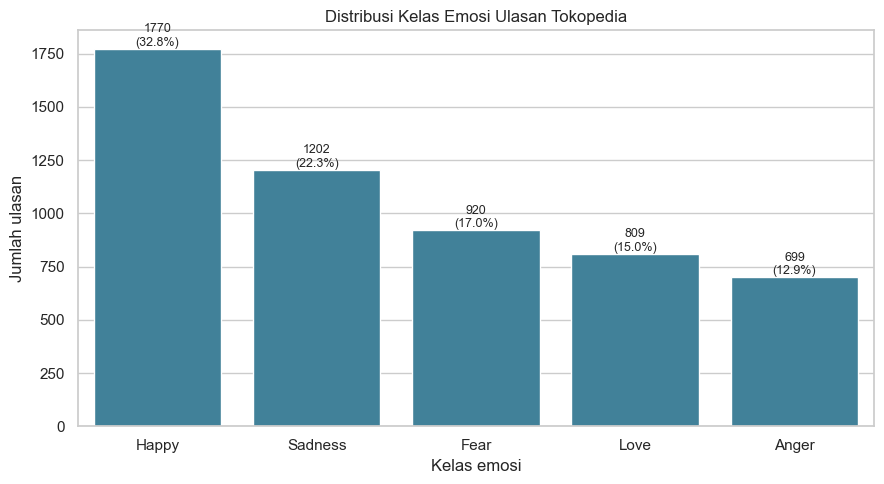

In [10]:
TARGET_COL = "Emotion"
TEXT_COL = "Customer Review"

emotion_counts = (
    df[TARGET_COL].dropna().astype(str).str.strip().str.title()
    .value_counts()
)

plt.figure(figsize=(9, 5))
ax = sns.barplot(x=emotion_counts.index, y=emotion_counts.values, color="#3288A8")
total = emotion_counts.sum()
for bar, count in zip(ax.patches, emotion_counts.values):
    pct = 100 * count / total if total else 0
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height(),
            f"{count}\n({pct:.1f}%)", ha="center", va="bottom", fontsize=9)
plt.title("Distribusi Kelas Emosi Ulasan Tokopedia")
plt.xlabel("Kelas emosi")
plt.ylabel("Jumlah ulasan")
plt.tight_layout()
plt.show()

### Interpretasi distribusi kelas emosi

Grafik ini menunjukkan jumlah dan proporsi ulasan pada setiap label emosi. Bandingkan tinggi batang untuk mengidentifikasi kelas mayoritas dan minoritas. Ketidakseimbangan kelas penting karena model dapat lebih mudah mempelajari kelas yang jumlahnya besar. Temuan ini menjadi alasan penggunaan Macro F1 sebagai metrik utama serta pembobotan kelas pada tahap modelling. Gunakan angka yang tercetak pada grafik sebagai dasar menyebut kelas dengan jumlah tertinggi dan terendah.

## Distribusi panjang ulasan

Statistik panjang ulasan:


,Jumlah Kata
count,5400.000000
mean,16.095000
std,15.647181
min,1.000000
25%,7.000000
50%,12.000000
75%,20.000000
max,184.000000


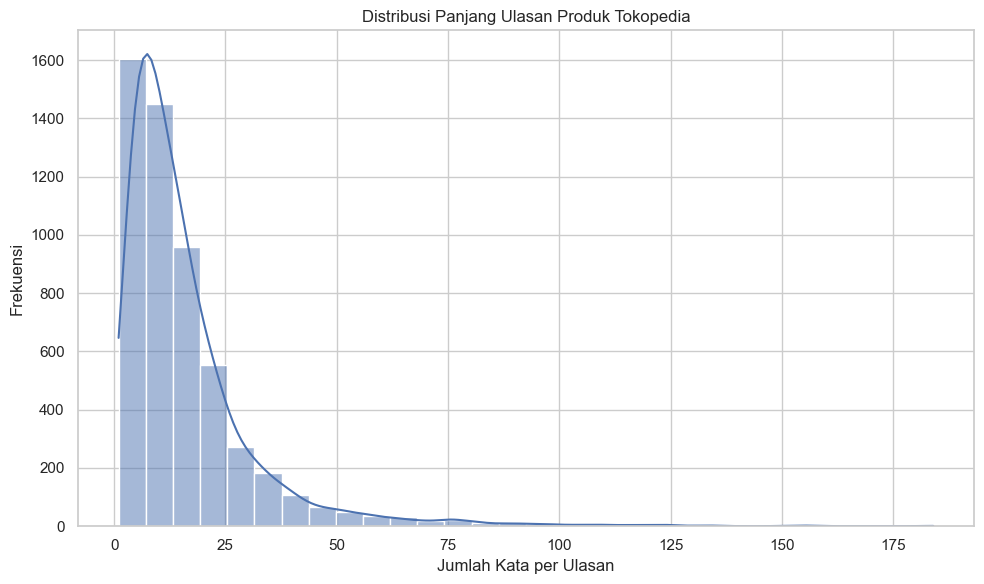

In [11]:
# Mengambil teks yang tidak kosong
reviews = df["Customer Review"].dropna().astype(str)

# Menghitung jumlah kata
review_word_count = reviews.str.split().str.len()

# Statistik deskriptif
print("Statistik panjang ulasan:")
display(review_word_count.describe().to_frame("Jumlah Kata"))

plt.figure(figsize=(10, 6))
sns.histplot(
    review_word_count,
    bins=30,
    kde=True
)
plt.title("Distribusi Panjang Ulasan Produk Tokopedia")
plt.xlabel("Jumlah Kata per Ulasan")
plt.ylabel("Frekuensi")
plt.tight_layout()
plt.show()

### Interpretasi panjang ulasan

Statistik dan visualisasi panjang ulasan memperlihatkan variasi jumlah kata pada teks. Ulasan sangat pendek berpotensi memiliki konteks terbatas, sedangkan ulasan panjang dapat memuat beberapa aspek pengalaman sekaligus. Informasi ini membantu memahami karakteristik teks sebelum normalisasi dan ekstraksi fitur. Panjang ulasan tidak dijadikan fitur prediksi pada eksperimen utama.

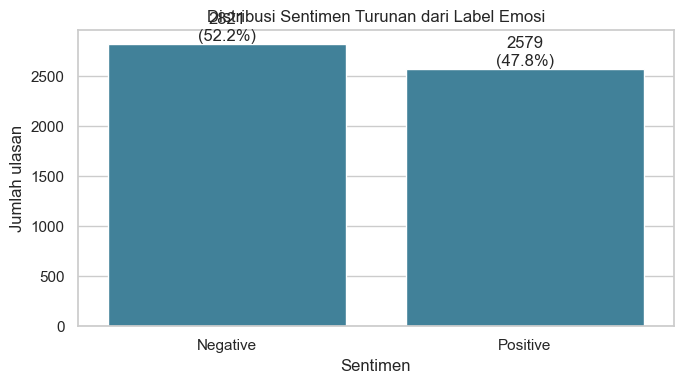

Catatan: sentimen di atas diturunkan dari Emotion. Jangan dipakai sebagai label independen.


In [12]:
# Pemetaan ini hanya ringkasan tambahan, bukan target model utama.
emotion_to_sentiment = {
    "Happy": "Positive",
    "Love": "Positive",
    "Sadness": "Negative",
    "Fear": "Negative",
    "Anger": "Negative"
}

emotion_clean_for_eda = (
    df[TARGET_COL].dropna().astype(str).str.strip().str.title()
)
sentiment_derived = emotion_clean_for_eda.map(emotion_to_sentiment).dropna()
sentiment_counts = sentiment_derived.value_counts().reindex(
    ["Negative", "Positive"], fill_value=0
)

plt.figure(figsize=(7, 4))
ax = sns.barplot(x=sentiment_counts.index, y=sentiment_counts.values, color="#3288A8")
total_sent = sentiment_counts.sum()
for bar, count in zip(ax.patches, sentiment_counts.values):
    pct = 100 * count / total_sent if total_sent else 0
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height(),
            f"{count}\n({pct:.1f}%)", ha="center", va="bottom")
plt.title("Distribusi Sentimen Turunan dari Label Emosi")
plt.xlabel("Sentimen")
plt.ylabel("Jumlah ulasan")
plt.tight_layout()
plt.show()

print("Catatan: sentimen di atas diturunkan dari Emotion. Jangan dipakai sebagai label independen.")

### Kata yang sering muncul per kelas emosi

Frekuensi kata berikut merupakan eksplorasi deskriptif. Kata yang sering muncul belum tentu menjadi fitur paling informatif, pemilihan fitur model dilakukan terpisah menggunakan TF-IDF dan Chi-Square.

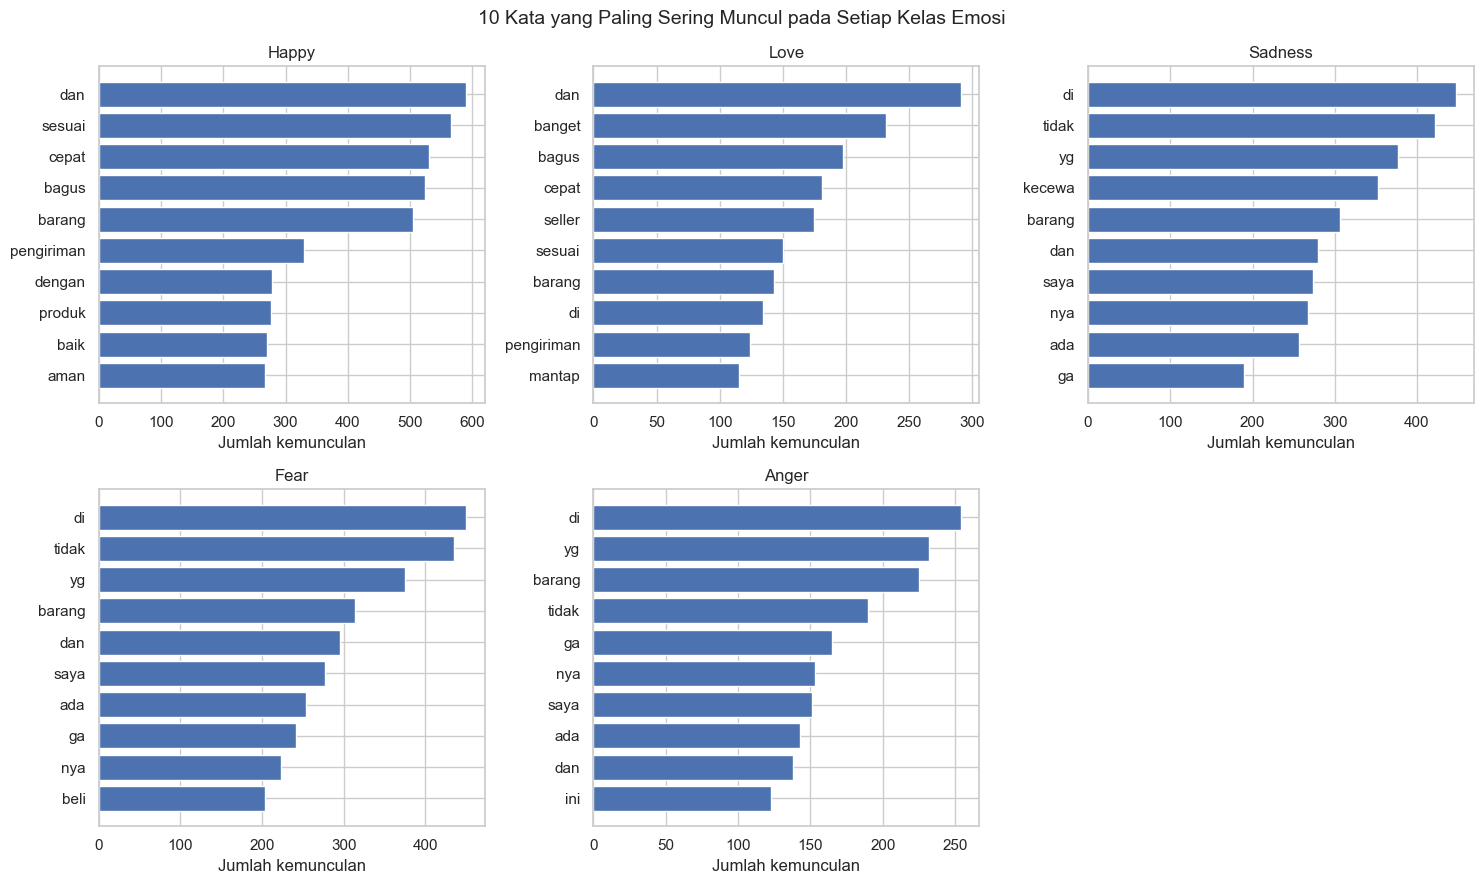

In [13]:
from collections import Counter

# Salinan untuk EDA; tidak mengubah dataset utama.
df_eda = df[["Customer Review", "Emotion"]].dropna().copy()
df_eda["review_clean"] = (
    df_eda["Customer Review"].astype(str).str.lower().str.strip()
)
df_eda["jumlah_kata"] = df_eda["review_clean"].str.split().str.len()
df_eda["jumlah_karakter"] = df_eda["review_clean"].str.len()

# Urutan tampilan EDA saja. Urutan encoding model ditentukan LabelEncoder.
emotion_order_eda = ["Happy", "Love", "Sadness", "Fear", "Anger"]

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()

for i, emotion in enumerate(emotion_order_eda):
    reviews = df_eda.loc[
        df_eda["Emotion"].astype(str).str.strip().str.title() == emotion,
        "review_clean"
    ]
    all_words = []
    for review in reviews:
        all_words.extend(re.findall(r"\b[a-zA-Z]+\b", review))

    top_words = Counter(all_words).most_common(10)
    if not top_words:
        axes[i].set_title(f"{emotion} (tidak ada data)")
        axes[i].axis("off")
        continue

    words, counts = zip(*top_words)
    axes[i].barh(list(words)[::-1], list(counts)[::-1])
    axes[i].set_title(emotion)
    axes[i].set_xlabel("Jumlah kemunculan")

plt.delaxes(axes[5])
plt.suptitle(
    "10 Kata yang Paling Sering Muncul pada Setiap Kelas Emosi",
    fontsize=14
)
plt.tight_layout()
plt.show()

### Interpretasi kata yang sering muncul

Frekuensi kata memperlihatkan istilah yang sering digunakan pada masing-masing kelas emosi. Kata yang sering muncul dapat memberi gambaran kosakata yang menonjol, tetapi frekuensi bukan bukti bahwa sebuah kata secara eksklusif mewakili satu emosi. Kata umum dapat muncul pada beberapa kelas, sehingga model memerlukan kombinasi unigram dan bigram melalui TF-IDF.

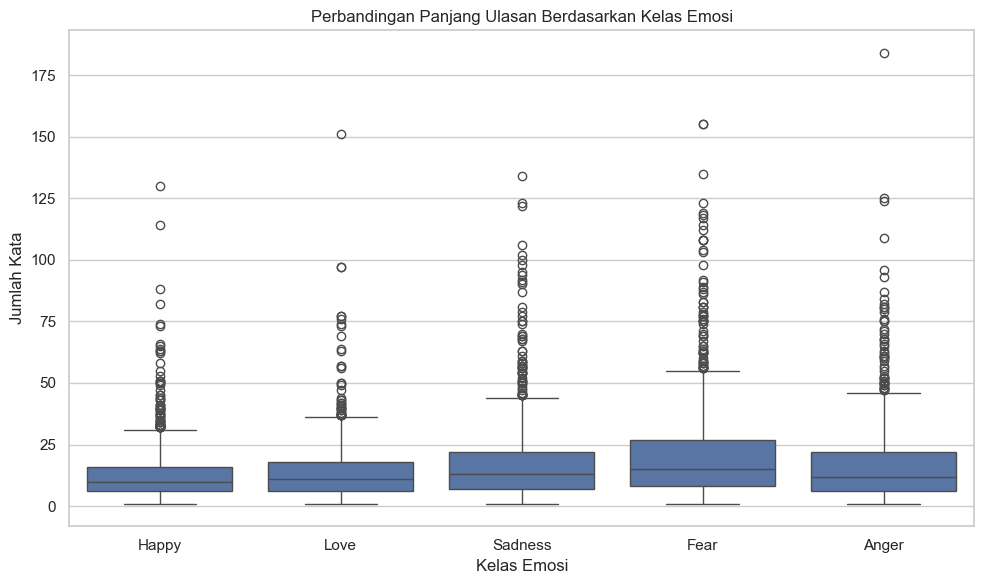

In [14]:
plt.figure(figsize=(10, 6))
sns.boxplot(
    data=df_eda,
    x="Emotion",
    y="jumlah_kata",
    order=["Happy", "Love", "Sadness", "Fear", "Anger"]
)
plt.title("Perbandingan Panjang Ulasan Berdasarkan Kelas Emosi")
plt.xlabel("Kelas Emosi")
plt.ylabel("Jumlah Kata")
plt.tight_layout()
plt.show()

### Interpretasi boxplot panjang ulasan per emosi

Boxplot membandingkan median, rentang antarkuartil, dan sebaran panjang ulasan pada tiap kelas. Tumpang tindih antarbox menunjukkan bahwa panjang teks saja belum tentu cukup untuk membedakan emosi. Karena itu, model utama tetap menggunakan representasi kata/ungkapan melalui TF-IDF, bukan hanya jumlah kata.

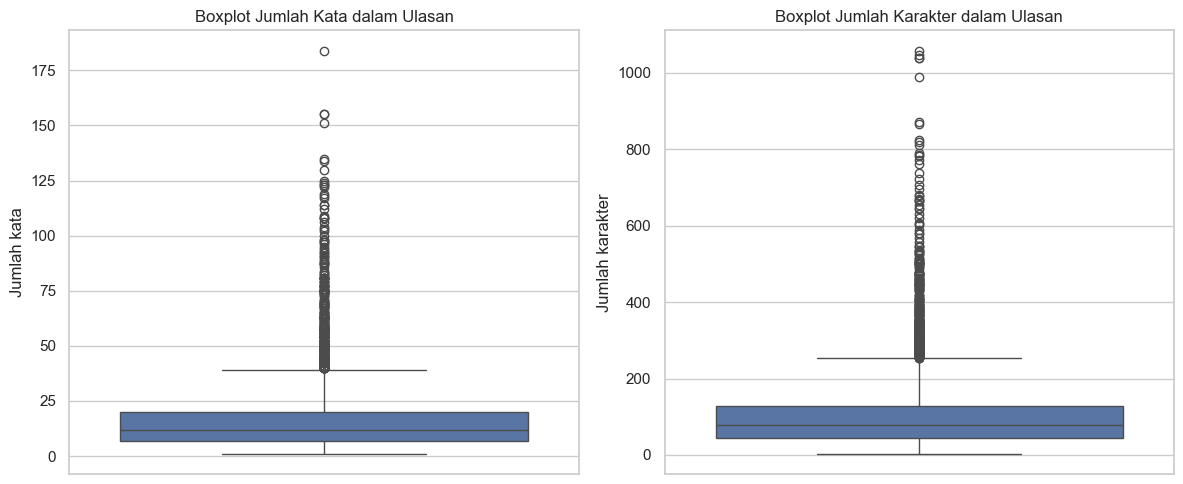

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.boxplot(
    y=df_eda["jumlah_kata"],
    ax=axes[0]
)
axes[0].set_title("Boxplot Jumlah Kata dalam Ulasan")
axes[0].set_ylabel("Jumlah kata")

sns.boxplot(
    y=df_eda["jumlah_karakter"],
    ax=axes[1]
)
axes[1].set_title("Boxplot Jumlah Karakter dalam Ulasan")
axes[1].set_ylabel("Jumlah karakter")
plt.tight_layout()
plt.show()

### Interpretasi sebaran panjang ulasan

Histogram dan boxplot membantu melihat kemencengan distribusi serta keberadaan ulasan yang jauh lebih panjang dibandingkan mayoritas. Titik di luar whisker boxplot merupakan indikasi statistik, bukan otomatis kesalahan data. Ulasan tetap dipertahankan selama teksnya valid dan tidak kosong setelah normalisasi.

In [16]:
# Membentuk fitur numerik dari teks ulasan
df_eda["rata_rata_panjang_kata"] = (
    df_eda["review_clean"]
    .apply(
        lambda teks: np.mean(
            [len(kata) for kata in teks.split()]
        ) if teks.split() else 0
    )
)

df_eda["jumlah_tanda_seru"] = (
    df_eda["review_clean"].str.count("!")
)

df_eda["jumlah_tanda_tanya"] = (
    df_eda["review_clean"].str.count(r"\?")
)

df_eda["jumlah_digit"] = (
    df_eda["review_clean"].str.count(r"\d")
)

fitur_numerik = [
    "jumlah_kata",
    "jumlah_karakter",
    "rata_rata_panjang_kata",
    "jumlah_tanda_seru",
    "jumlah_tanda_tanya",
    "jumlah_digit"
]

display(df_eda[fitur_numerik].describe().T)

,count,mean,std,min,25%,50%,75%,max
jumlah_kata,5400.0,16.095000,15.647181,1.000000,7.000000,12.000,20.00,184.0
jumlah_karakter,5400.0,103.806667,98.256865,3.000000,44.000000,78.000,128.00,1058.0
rata_rata_panjang_kata,5400.0,5.851025,1.827068,2.857143,5.049405,5.625,6.25,49.0
jumlah_tanda_seru,5400.0,0.168889,1.569645,0.000000,0.000000,0.000,0.00,99.0
jumlah_tanda_tanya,5400.0,0.695741,2.933829,0.000000,0.000000,0.000,0.00,90.0
jumlah_digit,5400.0,0.485000,1.400446,0.000000,0.000000,0.000,0.00,21.0


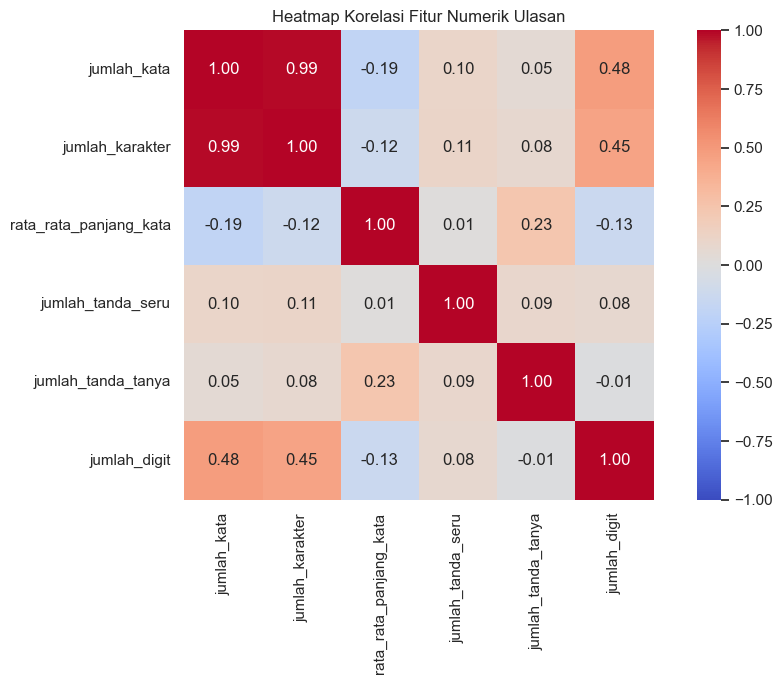

In [17]:
korelasi = df_eda[fitur_numerik].corr()

plt.figure(figsize=(10, 7))
sns.heatmap(
    korelasi,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1,
    square=True
)
plt.title("Heatmap Korelasi Fitur Numerik Ulasan")
plt.tight_layout()
plt.show()

### Interpretasi korelasi fitur numerik hasil rekayasa EDA

Heatmap menunjukkan korelasi linear antarvariabel numerik yang dianalisis. Korelasi yang tinggi berarti dua variabel memiliki pola perubahan linear yang searah atau berlawanan, tetapi tidak membuktikan hubungan sebab-akibat. Analisis ini bersifat eksploratif karena fitur numerik tersebut tidak menjadi input model klasifikasi teks.

### Representativitas dan potensi bias sampel

Periksa distribusi kategori, lokasi, dan nama produk. Jika distribusi sangat terkonsentrasi pada kategori/lokasi tertentu, model dapat lebih merepresentasikan kelompok tersebut. Dataset ini juga memuat ulasan produk dengan pengulangan nama produk, pemisahan berdasarkan produk digunakan untuk mengurangi kebocoran pola produk yang sama ke data uji. Distribusi dalam dataset tidak otomatis mewakili seluruh pengguna atau transaksi Tokopedia.

In [18]:
for col in ["Category", "Location", "Product Name"]:
    print(f"\n{col}: {df[col].nunique()} nilai unik")
    display(df[col].value_counts().head(15).rename("Jumlah").to_frame())

print("Proporsi 5 kategori terbesar (%):",
      round(df["Category"].value_counts(normalize=True).head(5).sum() * 100, 2))
print("Proporsi 5 lokasi terbesar (%):",
      round(df["Location"].value_counts(normalize=True).head(5).sum() * 100, 2))


Category: 29 nilai unik


,Jumlah
Category,
Computers and Laptops,200
Toys and Hobbies,200
Food and Drink,200
Office & Stationery,200
Automotive,200
Animal Care,200
Body Care,200
Party Supplies and Craft,200
Carpentry,200



Location: 61 nilai unik


,Jumlah
Location,
Jakarta Barat,1293
Jakarta Utara,873
Jakarta Pusat,471
Kota Tangerang,416
Kab. Tangerang,395
Jakarta Timur,372
Jakarta Selatan,297
Kota Tangerang Selatan,249
Kota Bekasi,189



Product Name: 1308 nilai unik


,Jumlah
Product Name,
Minigold Black Series Logam Mulia Koin Emas Mini 24 Karat 0.025 gram,25
lilin angka gold / Lilin Ultah emas / Lilin Angka ulang tahun gold - tiga,22
5-60kg Adjustable Handgrip Hand Grip Alat Fitness Olahraga Otot Tangan,22
Lem Balon / Perekat Balon / Ballon Glue,21
PACKING DUS + BUBBLE - TAMBAHAN DUS + BUBBLE,21
Cat tembok Interior Nucolour 25 kg tidak ngapur,20
South Korea Simcard korea selatan sim card kartu data internet Seoul,19
Lux Hand Sanitizer Jasmine 50ml,19
"Legging Stripe Anak Perempuan 7 - 13 Th / Leging Strip / Lejing Polos - Hitam, polos",19


Proporsi 5 kategori terbesar (%): 18.52
Proporsi 5 lokasi terbesar (%): 63.85


### Interpretasi keragaman kategori, lokasi, dan produk

Jumlah nilai unik dan frekuensi kategori/lokasi/produk menggambarkan keragaman cakupan dataset. Jika beberapa kategori atau produk mendominasi, hasil model mungkin lebih merepresentasikan kelompok tersebut. Penggunaan `Product Name` sebagai group split membantu menguji kemampuan generalisasi ke kelompok produk yang tidak muncul pada data latih.

## Analisis hubungan fitur dengan target

In [19]:
# Cramer's V untuk asosiasi fitur kategorikal dengan target
from scipy.stats import chi2_contingency

def cramers_v(x, y):
    tab = pd.crosstab(x, y)
    if tab.empty or min(tab.shape) < 2:
        return np.nan
    chi2_stat = chi2_contingency(tab)[0]
    n = tab.to_numpy().sum()
    denom = n * (min(tab.shape) - 1)
    return np.sqrt(chi2_stat / denom) if denom > 0 else np.nan

cat_candidates = ["Category", "Location", "Customer Rating", "Sentiment"]
assoc = []
for col in cat_candidates:
    assoc.append([col, cramers_v(df[col].fillna("Missing"), df["Emotion"].fillna("Missing"))])
display(pd.DataFrame(assoc, columns=["Fitur", "Cramer's V dengan Emotion"]).sort_values("Cramer's V dengan Emotion", ascending=False))

# Perbedaan numerik antarkelas: ringkasan median
for col in numeric_cols:
    print(f"\nMedian {col} menurut Emotion")
    display(df.groupby("Emotion")[col].median().rename("Median").to_frame())

,Fitur,Cramer's V dengan Emotion
3,Sentiment,1.000000
2,Customer Rating,0.510960
0,Category,0.208810
1,Location,0.163322



Median Price menurut Emotion


,Median
Emotion,
Anger,50000.0
Fear,59000.0
Happy,70000.0
Love,65000.0
Sadness,54888.0



Median Overall Rating menurut Emotion


,Median
Emotion,
Anger,4.9
Fear,4.9
Happy,4.9
Love,4.9
Sadness,4.9



Median Number Sold menurut Emotion


,Median
Emotion,
Anger,6132.0
Fear,4504.5
Happy,2915.5
Love,3320.0
Sadness,4635.0



Median Total Review menurut Emotion


,Median
Emotion,
Anger,1877.0
Fear,1454.0
Happy,999.0
Love,911.0
Sadness,1382.0



Median Customer Rating menurut Emotion


,Median
Emotion,
Anger,1.0
Fear,1.0
Happy,5.0
Love,5.0
Sadness,1.0


### Interpretasi asosiasi fitur kategorikal dengan target

Ukuran asosiasi seperti Cramer's V merangkum kekuatan hubungan antara variabel kategorikal dan label emosi. Nilai asosiasi tidak menunjukkan sebab-akibat dan tidak otomatis menjadikan variabel tersebut layak sebagai fitur prediksi. Secara khusus, `Sentiment` tidak dimasukkan ke model karena hubungannya yang dekat dengan label emosi dapat menyebabkan target leakage.

Interpretasi asosiasi harus mempertimbangkan definisi variabel. `Sentiment` diperiksa untuk mendeteksi potensi kebocoran target, bukan untuk dimasukkan ke model. `Customer Rating` dapat berkaitan dengan emosi, tetapi tetap perlu diuji apakah rating tersedia pada saat prediksi dilakukan. Untuk tugas klasifikasi teks, model utama di bawah hanya menggunakan teks ulasan agar tujuan prediksi konsisten.

## Data cleaning dan perbandingan

In [20]:
df_copy = df.copy()
n_before = len(df)
missing_before = int(df.isna().sum().sum())
duplicate_before = int(df.duplicated().sum())
repeated_review_before = int(df["Customer Review"].duplicated().sum())

# Buang hanya baris duplikat penuh.
df = df.drop_duplicates().copy()

# Baris tanpa teks atau target tidak dapat digunakan untuk supervised text classification.
df["Customer Review"] = df["Customer Review"].astype("string")
df["Emotion"] = df["Emotion"].astype("string")
df = df.dropna(subset=["Customer Review", "Emotion"]).copy()
df["Customer Review"] = df["Customer Review"].str.strip()
df = df[df["Customer Review"].ne("")].copy()

# Normalisasi teks minimal: Unicode/karakter whitespace, lowercase, dan spasi berulang.
# Ejaan informal, negasi, emoji, dan tanda baca tidak dihapus agresif agar konteks ulasan terjaga.
def normalize_review(text):
    text = str(text).replace("\uFFFD", " ")
    text = text.lower()
    text = re.sub(r"\s+", " ", text).strip()
    return text

df["review_clean"] = df["Customer Review"].map(normalize_review)

n_after = len(df)
comparison = pd.DataFrame({
    "Kondisi": ["Jumlah baris", "Missing seluruh sel", "Duplikasi baris penuh", "Teks ulasan berulang"],
    "Sebelum": [n_before, missing_before, duplicate_before, repeated_review_before],
    "Sesudah": [n_after, int(df.isna().sum().sum()), int(df.duplicated().sum()),
                int(df["Customer Review"].duplicated().sum())]
})
comparison["Perubahan"] = comparison["Sesudah"] - comparison["Sebelum"]
display(comparison)
print("Jumlah karakter pengganti Unicode U+FFFD pada data asli:",
      int(df["Customer Review"].astype(str).str.contains("\uFFFD", regex=False).sum()))

,Kondisi,Sebelum,Sesudah,Perubahan
0,Jumlah baris,5400,5393,-7
1,Missing seluruh sel,0,0,0
2,Duplikasi baris penuh,7,0,-7
3,Teks ulasan berulang,95,88,-7


Jumlah karakter pengganti Unicode U+FFFD pada data asli: 85


In [21]:
# df sudah dibersihkan dari duplikasi baris penuh pada tahap sebelumnya.
# Tidak perlu menghapus duplikasi penuh untuk kedua kalinya.
df_clean = df.copy().reset_index(drop=True)

print("Jumlah data setelah cleaning awal:", len(df_clean))

Jumlah data setelah cleaning awal: 5393


In [22]:
# Normalisasi teks dibuat konsisten untuk training dan deployment.
# Tidak menghapus negasi, tanda baca, atau karakter non-ASCII secara agresif.
df_clean["clean_review"] = df_clean["Customer Review"].map(normalize_review)

# Rapikan label target.
df_clean["Emotion"] = (
    df_clean["Emotion"]
    .astype(str)
    .str.strip()
    .str.title()
)

In [23]:
# Menghapus teks yang kosong setelah normalisasi.
empty_reviews = int(df_clean["clean_review"].eq("").sum())
print("Jumlah teks kosong:", empty_reviews)

df_clean = df_clean.loc[df_clean["clean_review"].ne("")].copy()
df_clean = df_clean.reset_index(drop=True)

print("Jumlah data setelah preprocessing:", len(df_clean))
display(df_clean["Emotion"].value_counts().to_frame("Jumlah Data"))

Jumlah teks kosong: 0
Jumlah data setelah preprocessing: 5393


,Jumlah Data
Emotion,
Happy,1768
Sadness,1201
Fear,918
Love,808
Anger,698


Duplikasi teks ulasan tidak otomatis dihapus karena teks yang sama dapat muncul pada produk atau konteks berbeda. Duplikasi baris penuh dihapus. Nilai numerik ekstrem dipertahankan karena belum ada bukti bahwa nilai tersebut tidak valid. Normalisasi teks dibuat konservatif agar negasi dan informasi emosi tidak hilang.

## Menentukan fitur dan target

In [24]:
# teks ulasan yang telah dinormalisasi.
X = df_clean["clean_review"].astype(str)

# Target masih berupa label teks pada tahap ini.
y_text = df_clean["Emotion"].astype(str)

print("Jumlah data fitur :", len(X))
print("Jumlah data target:", len(y_text))
print("Kelas emosi:", sorted(y_text.unique()))

Jumlah data fitur : 5393
Jumlah data target: 5393
Kelas emosi: ['Anger', 'Fear', 'Happy', 'Love', 'Sadness']


### Keputusan seleksi fitur dan alasannya

| Kolom/fitur | Keputusan | Alasan |
|---|---|---|
| `Customer Review` / `clean_review` | Dipertahankan | Sumber informasi bahasa yang digunakan untuk memprediksi emosi. |
| `Emotion` | Target (y) | Label yang ingin diprediksi, bukan fitur input. |
| `Product Name` | Hanya untuk grup split | Mencegah produk yang sama tersebar pada train dan test; tidak digunakan model. |
| `Sentiment` | Dikeluarkan dari X | Sangat berkaitan dengan label emosi dan berisiko menyebabkan target leakage. |
| `Category`, `Location`, `Price`, `Overall Rating`, `Number Sold`, `Total Review`, `Customer Rating` | Tidak digunakan sebagai input utama | Eksperimen difokuskan pada klasifikasi berdasarkan teks ulasan; metadata tidak dicampurkan ke ruang fitur teks. |
| Token TF-IDF | Disaring dengan Chi-Square | Memilih hingga 3.000 fitur yang paling informatif terhadap target berdasarkan skor Chi-Square. |

Dengan demikian, feature selection dilakukan pada dua tingkat: pemilihan kolom dataset berdasarkan tujuan penelitian, lalu pemilihan token/n-gram TF-IDF menggunakan Chi-Square. Nilai k=3.000 ditetapkan sebagai konfigurasi eksperimen, bukan dipilih dengan melihat data test.


## Split data

In [25]:
from sklearn.model_selection import GroupShuffleSplit

# Nama produk hanya digunakan sebagai grup, bukan sebagai fitur model.
groups = (
    df_clean["Product Name"]
    .fillna("UNKNOWN_PRODUCT")
    .astype(str)
    .reset_index(drop=True)
)

split_found = False
all_emotions = np.sort(y_text.unique())

for seed in range(42, 242):
    splitter = GroupShuffleSplit(
        n_splits=1,
        test_size=0.20,
        random_state=seed
    )
    train_idx, test_idx = next(
        splitter.split(X, y_text, groups=groups)
    )

    train_classes = np.unique(y_text.iloc[train_idx])
    test_classes = np.unique(y_text.iloc[test_idx])

    if (
        len(train_classes) == len(all_emotions)
        and len(test_classes) == len(all_emotions)
    ):
        split_found = True
        break

if not split_found:
    raise ValueError(
        "Tidak ditemukan pembagian group train-test yang memuat seluruh "
        "kelas emosi pada kedua subset. Periksa distribusi kelas per produk."
    )

X_train = X.iloc[train_idx].reset_index(drop=True)
X_test = X.iloc[test_idx].reset_index(drop=True)
y_train_text = y_text.iloc[train_idx].reset_index(drop=True)
y_test_text = y_text.iloc[test_idx].reset_index(drop=True)
groups_train = groups.iloc[train_idx].reset_index(drop=True)

train_groups = set(groups.iloc[train_idx])
test_groups = set(groups.iloc[test_idx])
assert train_groups.isdisjoint(test_groups)

print("Seed split terpilih:", seed)
print("Jumlah data training:", len(X_train))
print("Jumlah data testing :", len(X_test))
print("Kelas training:", sorted(y_train_text.unique()))
print("Kelas testing :", sorted(y_test_text.unique()))
print("Irisan grup produk train-test:", len(train_groups.intersection(test_groups)))

# Pemeriksaan tambahan: teks identik lintas produk dapat tetap muncul
# pada kedua subset. Ini dilaporkan, bukan dihapus otomatis.
overlap_text = set(X_train).intersection(set(X_test))
print("Jumlah teks identik lintas training-testing:", len(overlap_text))
if overlap_text:
    print(
        "Catatan: beberapa teks identik dapat muncul pada produk berbeda. "
        "Interpretasikan hasil dengan mempertimbangkan keterbatasan ini."
    )

Seed split terpilih: 42
Jumlah data training: 4399
Jumlah data testing : 994
Kelas training: ['Anger', 'Fear', 'Happy', 'Love', 'Sadness']
Kelas testing : ['Anger', 'Fear', 'Happy', 'Love', 'Sadness']
Irisan grup produk train-test: 0
Jumlah teks identik lintas training-testing: 12
Catatan: beberapa teks identik dapat muncul pada produk berbeda. Interpretasikan hasil dengan mempertimbangkan keterbatasan ini.


### Alasan pembagian data berbasis grup

GroupShuffleSplit digunakan agar seluruh baris dengan `Product Name` yang sama berada pada satu subset. Ini mengurangi risiko model menghafal karakteristik produk yang sama pada train dan test. Pembagian dilakukan dua tahap: train-test, kemudian train dibagi menjadi subtraining-validation. Proporsi keseluruhan secara teoritis sekitar 64% subtraining, 16% validation, dan 20% test, meskipun rasio aktual dapat sedikit berbeda karena unit pembagiannya adalah grup produk.

## Encoding

In [26]:
from sklearn.preprocessing import LabelEncoder

# Encoder hanya di-fit pada label training.
le = LabelEncoder()
y_train = le.fit_transform(y_train_text)
y_test = le.transform(y_test_text)

# seluruh evaluasi dan visualisasi menggunakan urutan ini.
class_names = list(le.classes_)

print("Pemetaan label:")
for code, emotion in enumerate(class_names):
    print(f"{code} = {emotion}")

print("Jumlah y_train:", y_train.shape)
print("Jumlah y_test :", y_test.shape)

Pemetaan label:
0 = Anger
1 = Fear
2 = Happy
3 = Love
4 = Sadness
Jumlah y_train: (4399,)
Jumlah y_test : (994,)


### Alasan Label Encoding

LabelEncoder mengubah label teks emosi menjadi kode numerik agar dapat diproses algoritma. Encoder di-fit pada label training, lalu diterapkan ke validation dan testing. Kode angka tersebut hanya representasi kategori, bukan urutan tingkat emosi.

`GroupShuffleSplit` dipilih karena beberapa ulasan berasal dari nama produk yang sama. Rasio aktual dapat sedikit berbeda dari 80:20 karena unit pemisahan adalah grup produk, bukan baris. Data uji disimpan dan tidak dipakai untuk memilih fitur maupun melatih model.

### Analisis dan pembobotan kelas

In [27]:
from sklearn.utils.class_weight import compute_class_weight, compute_sample_weight

# Bobot kelas dihitung hanya dari data training.
classes = np.arange(len(class_names))

bobot_kelas = (
    pd.Series(y_train)
    .value_counts()
    .reindex(classes, fill_value=0)
    .sort_index()
)

bobot_kelas_array = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weight_dict = dict(zip(classes, bobot_kelas_array))
sample_weights = compute_sample_weight(
    class_weight="balanced",
    y=y_train
)

weight_table = pd.DataFrame({
    "Emotion": class_names,
    "Jumlah train": bobot_kelas.to_numpy(),
    "Bobot kelas": bobot_kelas_array
})
weight_table["Kontribusi efektif (%)"] = (
    weight_table["Jumlah train"] * weight_table["Bobot kelas"]
    / (weight_table["Jumlah train"] * weight_table["Bobot kelas"]).sum()
    * 100
)

display(weight_table)
print("Jumlah sampel sebelum weighting:", len(y_train))
print("Jumlah bobot sampel:", len(sample_weights))

,Emotion,Jumlah train,Bobot kelas,Kontribusi efektif (%)
0,Anger,570,1.543509,20.0
1,Fear,761,1.156110,20.0
2,Happy,1434,0.613529,20.0
3,Love,651,1.351459,20.0
4,Sadness,983,0.895015,20.0


Jumlah sampel sebelum weighting: 4399
Jumlah bobot sampel: 4399


### Interpretasi pembobotan kelas

Bobot kelas dihitung dari distribusi label pada subset training yang relevan. Kelas yang lebih jarang memperoleh bobot lebih besar sehingga kesalahan pada kelas minoritas mendapat perhatian lebih saat training. Class weighting tidak menambah atau menghapus baris data. Kinerja akhirnya tetap harus diperiksa menggunakan Macro F1 dan metrik per kelas.

Class weighting dipakai untuk mengurangi dominasi kelas mayoritas tanpa mengubah jumlah atau komposisi sampel. Bobot dihitung hanya dari label training. TF-IDF menggunakan normalisasi L2 secara default, sehingga tidak ditambahkan StandardScaler/MinMaxScaler pada matriks teks sparse. Fitur numerik tidak digabungkan ke model teks utama.

## TF-IDF dan seleksi fitur Chi-Square

**Catatan alur preprocessing:** TF-IDF tidak di-*fit* pada seluruh data training sebelum validasi internal. "
"Pada eksperimen validasi, TF-IDF di-*fit* hanya pada subtraining (Cell 55), lalu validation di-*transform*. "
"Pada setiap lipatan GroupKFold, TF-IDF juga di-*fit* ulang hanya pada bagian latih lipatan (Cell 60). "
"Setelah model dipilih, TF-IDF di-*fit* ulang pada seluruh data training untuk training akhir (Cell 66).

### Validasi internal dan pemilihan model

Data training dibagi lagi menjadi subtraining dan validation berdasarkan grup produk. Validation set disimpan untuk membandingkan Random Forest dan XGBoost setelah hyperparameter tuning. TF-IDF dan Chi-Square pada eksperimen validasi hanya di-*fit* pada subtraining.

Jumlah fitur Chi-Square (`k`) ditetapkan sebesar 3.000 sebagai konfigurasi eksperimen akhir, bukan dipilih menggunakan validation set. Hyperparameter model dituning menggunakan GroupKFold pada subtraining. Dengan demikian, validation set hanya digunakan untuk membandingkan kedua model, sedangkan data testing akhir hanya digunakan untuk evaluasi final.

Setelah model terpilih, TF-IDF dan Chi-Square di-*fit* ulang pada seluruh data training. Kedua model kemudian dilatih ulang pada seluruh data training dan dievaluasi pada data testing yang disimpan sejak awal.

In [28]:
from sklearn.model_selection import GroupShuffleSplit

# Validasi internal berbasis grup produk pada data training saja.
y_train_array = np.asarray(y_train)
groups_train_array = np.asarray(groups_train)
class_codes = np.arange(len(class_names))

split_found = False
for inner_seed in range(42, 242):
    inner_splitter = GroupShuffleSplit(
        n_splits=1,
        test_size=0.20,
        random_state=inner_seed
    )
    sub_idx, val_idx = next(
        inner_splitter.split(
            X_train,
            y_train_array,
            groups_train_array
        )
    )

    if (
        len(np.unique(y_train_array[sub_idx])) == len(class_codes)
        and len(np.unique(y_train_array[val_idx])) == len(class_codes)
    ):
        split_found = True
        break

if not split_found:
    raise ValueError(
        "Tidak ditemukan pembagian internal yang memuat semua kelas pada "
        "subtraining dan validation. Periksa distribusi kelas per produk."
    )

X_sub_text = X_train.iloc[sub_idx].reset_index(drop=True)
X_val_text = X_train.iloc[val_idx].reset_index(drop=True)
y_sub = y_train_array[sub_idx]
y_val = y_train_array[val_idx]

print("Seed validasi terpilih:", inner_seed)
print("Jumlah subtraining:", len(X_sub_text))
print("Jumlah validation :", len(X_val_text))
print("Kelas subtraining:", np.unique(y_sub))
print("Kelas validation :", np.unique(y_val))

Seed validasi terpilih: 42
Jumlah subtraining: 3654
Jumlah validation : 745
Kelas subtraining: [0 1 2 3 4]
Kelas validation : [0 1 2 3 4]


In [29]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.feature_selection import SelectKBest, chi2
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)

# TF-IDF di-fit hanya pada subtraining.
tfidf_inner = TfidfVectorizer(
    lowercase=False,
    ngram_range=(1, 2),
    min_df=2,
    max_features=30000,
    sublinear_tf=True,
    norm="l2"
)

X_sub_tfidf = tfidf_inner.fit_transform(X_sub_text)
X_val_tfidf = tfidf_inner.transform(X_val_text)

print("TF-IDF subtraining:", X_sub_tfidf.shape)
print("TF-IDF validation :", X_val_tfidf.shape)

# Jumlah fitur ditetapkan sebelum membandingkan model pada validation.
# Nilai 3.000 menjadi konfigurasi tetap pada eksperimen akhir ini.
REQUESTED_K = 3000
best_k = min(REQUESTED_K, X_sub_tfidf.shape[1])

if best_k < 1:
    raise ValueError("Tidak ada fitur TF-IDF yang dapat digunakan.")

print("Jumlah fitur Chi-Square yang digunakan:", best_k)


TF-IDF subtraining: (3654, 8637)
TF-IDF validation : (745, 8637)
Jumlah fitur Chi-Square yang digunakan: 3000


### Alasan TF-IDF dan Chi-Square

TF-IDF mengubah teks menjadi representasi numerik berbasis bobot kata dan n-gram. Konfigurasi unigram-bigram memungkinkan model mengenali kata tunggal maupun gabungan kata. Normalisasi L2 diterapkan oleh TF-IDF sehingga StandardScaler atau MinMaxScaler tidak diperlukan untuk matriks sparse ini.

Chi-Square digunakan sebagai metode filter feature selection untuk memilih token yang memiliki asosiasi statistik dengan kelas target. Fitting TF-IDF dan seleksi fitur dilakukan hanya pada subset training di setiap tahap validasi agar informasi validation/test tidak ikut membentuk representasi fitur.

# Fase 4 — Modeling (CRISP-DM)

## Pemilihan model

Tujuan bisnis (Business Understanding) adalah mengklasifikasikan ulasan ke **5 kelas emosi** dengan **Macro F1** sebagai metrik utama. Data berupa teks yang diubah menjadi matriks **TF-IDF** (sparse, berdimensi tinggi, 3.000 fitur setelah Chi-Square) dan kelasnya **tidak seimbang**. Dua model dipilih:

| Model | Asal materi | Mengapa cocok untuk data dan tujuan ini | Keterbatasan |
|---|---|---|---|
| **Random Forest** | Supervised Learning: Decision Tree dan Random Forest (praktikum) | Kumpulan banyak pohon keputusan (*bagging*), sehingga stabil terhadap *noise* dan tidak mudah overfitting pada fitur teks yang jarang (sparse). Mendukung `class_weight` untuk kelas tidak seimbang. Menghasilkan *feature importance*. | Pohon dibangun independen, sehingga kurang kuat menangkap pola halus pada kelas minoritas. |
| **XGBoost** | Pengembangan *gradient boosting* dari pohon keputusan yang sama | Pohon dibangun **berurutan**, setiap pohon memperbaiki kesalahan pohon sebelumnya. Cocok untuk membedakan emosi yang mirip (Fear, Sadness, Anger). Mendukung `sample_weight` untuk kelas tidak seimbang. | Lebih banyak parameter, sehingga perlu tuning agar tidak overfitting. |
| *Baseline* | Model pembanding | Selalu menebak kelas mayoritas. Menjadi batas bawah yang harus dilampaui. | Tidak mempelajari pola apa pun. |

**Alasan memakai dua model:** Random Forest mewakili pendekatan *bagging* (menurunkan varians) dan XGBoost mewakili pendekatan *boosting* (menurunkan bias). Keduanya berbasis pohon, sehingga perbedaan hasilnya mencerminkan perbedaan strategi ensemble, bukan perbedaan jenis fitur. Model terbaik dipilih secara objektif berdasarkan **Macro F1 pada validation set**, bukan berdasarkan data uji.

## Pengaturan *random state* dan lingkungan

Semua proses acak memakai satu nilai `SEED = 42` (split data, Random Forest, XGBoost, baseline), sehingga hasil **sama setiap notebook dijalankan ulang**. Versi library dicetak karena hasil yang persis sama hanya dijamin pada versi library yang sama.

In [30]:
import random, platform, sklearn, xgboost
from sklearn.ensemble import RandomForestClassifier
from sklearn.utils.class_weight import compute_class_weight, compute_sample_weight
from xgboost import XGBClassifier

# Satu seed global agar hasil identik setiap kali notebook dijalankan ulang.
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Parameter TF-IDF disimpan satu kali agar tahap tuning memakai konfigurasi yang sama.
TFIDF_PARAMS = dict(
    lowercase=False, ngram_range=(1, 2), min_df=2,
    max_features=30000, sublinear_tf=True, norm="l2"
)

# Target keberhasilan dari Business Understanding.
TARGET_MACRO_F1 = 0.50

# Parameter XGBoost yang dibuat tetap (tidak dituning).
XGB_FIXED = dict(
    objective="multi:softprob", num_class=len(class_names),
    learning_rate=0.08, subsample=0.85, colsample_bytree=0.85,
    reg_lambda=1.0, eval_metric="mlogloss", tree_method="hist",
    random_state=SEED, n_jobs=-1
)

print("Python  :", platform.python_version())
print("sklearn :", sklearn.__version__)
print("xgboost :", xgboost.__version__)
print("SEED    :", SEED)

Python  : 3.10.11
sklearn : 1.7.2
xgboost : 3.2.0
SEED    : 42


## Pengaturan parameter (*hyperparameter tuning*)

Parameter model diuji secara sistematis dengan prosedur berikut:

1. **Data yang dipakai:** hanya *subtraining* (bagian dari data train). Validation dan data uji tidak digunakan dalam proses tuning.
2. **Validasi silang berbasis grup (`GroupKFold`, 5 lipatan):** produk yang sama tidak pernah berada di lipatan latih dan lipatan evaluasi sekaligus.
3. **Tanpa kebocoran:** pada setiap lipatan, TF-IDF dan Chi-Square di-*fit* hanya pada bagian latih lipatan tersebut.
4. **Jumlah fitur:** `k=3.000` ditetapkan sebagai konfigurasi eksperimen akhir, bukan dipilih dari validation set.
5. **Parameter model:** setiap kombinasi pada *grid* dinilai menggunakan rata-rata Macro F1 lintas lipatan. Kombinasi terbaik untuk setiap algoritma dipilih berdasarkan skor CV tertinggi.

Grid yang diuji:
- **Random Forest:** `n_estimators` (jumlah pohon), `max_features` (jumlah fitur yang dipertimbangkan pada setiap pemisahan), dan `min_samples_leaf` (jumlah minimum sampel pada daun).
- **XGBoost:** `max_depth` (kedalaman pohon) dan `n_estimators` (jumlah putaran boosting).

Parameter awal sebelumnya (RF: 400 / sqrt / 1; XGBoost: depth 6 / 350 pohon) ikut masuk grid, sehingga dampak tuning dapat dibandingkan langsung.

In [31]:
from sklearn.model_selection import GroupKFold

N_FOLDS = 5
groups_sub = groups_train_array[sub_idx]          # grup produk milik subtraining
gkf = GroupKFold(n_splits=N_FOLDS)                # deterministik, tanpa pengacakan

# Menyiapkan matriks fitur tiap lipatan SATU KALI agar tuning hemat waktu.
# TF-IDF dan Chi-Square di-fit hanya pada bagian latih tiap lipatan.
fold_data = []
for fold, (fit_idx, hold_idx) in enumerate(gkf.split(X_sub_text, y_sub, groups_sub), start=1):
    tfidf_f = TfidfVectorizer(**TFIDF_PARAMS)
    Xf_fit = tfidf_f.fit_transform(X_sub_text.iloc[fit_idx])
    Xf_hold = tfidf_f.transform(X_sub_text.iloc[hold_idx])

    sel_f = SelectKBest(score_func=chi2, k=min(best_k, Xf_fit.shape[1]))
    Xf_fit = sel_f.fit_transform(Xf_fit, y_sub[fit_idx])
    Xf_hold = sel_f.transform(Xf_hold)

    assert len(np.unique(y_sub[fit_idx])) == len(class_names), "Ada kelas hilang di lipatan latih"
    fold_data.append({
        "X_fit": Xf_fit, "y_fit": y_sub[fit_idx],
        "X_hold": Xf_hold, "y_hold": y_sub[hold_idx],
    })
    print(f"Lipatan {fold}: latih={len(fit_idx)}, uji lipatan={len(hold_idx)}, "
          f"kelas uji lipatan={np.unique(y_sub[hold_idx]).tolist()}")

Lipatan 1: latih=2923, uji lipatan=731, kelas uji lipatan=[0, 1, 2, 3, 4]
Lipatan 2: latih=2923, uji lipatan=731, kelas uji lipatan=[0, 1, 2, 3, 4]
Lipatan 3: latih=2923, uji lipatan=731, kelas uji lipatan=[0, 1, 2, 3, 4]
Lipatan 4: latih=2923, uji lipatan=731, kelas uji lipatan=[0, 1, 2, 3, 4]
Lipatan 5: latih=2924, uji lipatan=730, kelas uji lipatan=[0, 1, 2, 3, 4]


Waktu tuning: 629 detik


,Model,Parameter,Macro F1 CV (rata-rata),Simpangan baku,Parameter awal
0,Random Forest,"{'n_estimators': 400, 'max_features': 'log2', ...",0.5531,0.0250,False
1,Random Forest,"{'n_estimators': 200, 'max_features': 'log2', ...",0.5526,0.0205,False
2,Random Forest,"{'n_estimators': 400, 'max_features': 'sqrt', ...",0.5466,0.0262,False
3,Random Forest,"{'n_estimators': 200, 'max_features': 'sqrt', ...",0.5443,0.0260,False
4,Random Forest,"{'n_estimators': 400, 'max_features': 'sqrt', ...",0.4933,0.0126,True
5,Random Forest,"{'n_estimators': 200, 'max_features': 'sqrt', ...",0.4905,0.0117,False
6,Random Forest,"{'n_estimators': 400, 'max_features': 'log2', ...",0.4692,0.0202,False
7,Random Forest,"{'n_estimators': 200, 'max_features': 'log2', ...",0.4670,0.0121,False
8,XGBoost,"{'max_depth': 3, 'n_estimators': 350}",0.5457,0.0176,False
9,XGBoost,"{'max_depth': 6, 'n_estimators': 350}",0.5451,0.0180,True


Parameter terbaik Random Forest: {'n_estimators': 400, 'max_features': 'log2', 'min_samples_leaf': 3}
Parameter terbaik XGBoost      : {'max_depth': 3, 'n_estimators': 350}


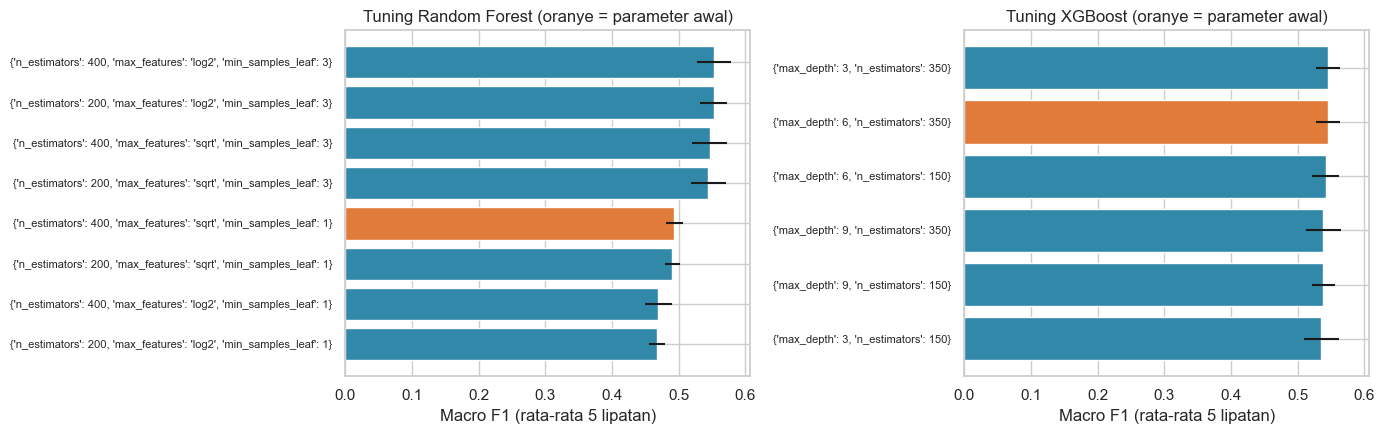

In [32]:
from itertools import product
import time

rf_grid = {
    "n_estimators": [200, 400],
    "max_features": ["sqrt", "log2"],
    "min_samples_leaf": [1, 3],
}
xgb_grid = {
    "max_depth": [3, 6, 9],
    "n_estimators": [150, 350],
}
rf_default = {"n_estimators": 400, "max_features": "sqrt", "min_samples_leaf": 1}
xgb_default = {"max_depth": 6, "n_estimators": 350}

def expand(grid):
    keys = list(grid)
    return [dict(zip(keys, vals)) for vals in product(*grid.values())]

def cv_macro_f1(build_model, weighted_by_sample):
    """Rata-rata dan simpangan baku Macro F1 pada seluruh lipatan GroupKFold."""
    scores = []
    for fd in fold_data:
        model = build_model()
        if weighted_by_sample:
            w = compute_sample_weight("balanced", fd["y_fit"])
            model.fit(fd["X_fit"], fd["y_fit"], sample_weight=w)
        else:
            model.fit(fd["X_fit"], fd["y_fit"])
        pred = model.predict(fd["X_hold"])
        scores.append(f1_score(fd["y_hold"], pred, average="macro",
                               labels=np.arange(len(class_names)), zero_division=0))
    return float(np.mean(scores)), float(np.std(scores))

rows = []
t0 = time.time()
for p in expand(rf_grid):
    m, s = cv_macro_f1(
        lambda p=p: RandomForestClassifier(class_weight="balanced", random_state=SEED, n_jobs=-1, **p),
        weighted_by_sample=False)
    rows.append({"Model": "Random Forest", "Parameter": str(p), "Macro F1 CV (rata-rata)": m,
                 "Simpangan baku": s, "Parameter awal": p == rf_default, "params": p})
for p in expand(xgb_grid):
    m, s = cv_macro_f1(
        lambda p=p: XGBClassifier(**XGB_FIXED, **p),
        weighted_by_sample=True)
    rows.append({"Model": "XGBoost", "Parameter": str(p), "Macro F1 CV (rata-rata)": m,
                 "Simpangan baku": s, "Parameter awal": p == xgb_default, "params": p})
print(f"Waktu tuning: {time.time() - t0:.0f} detik")

tuning_df = pd.DataFrame(rows)
tuning_show = (tuning_df.drop(columns="params")
               .sort_values(["Model", "Macro F1 CV (rata-rata)"], ascending=[True, False])
               .reset_index(drop=True))
display(tuning_show.round(4))

# Parameter terbaik tiap model = Macro F1 CV tertinggi.
best_rf_params = tuning_df[tuning_df.Model == "Random Forest"].sort_values(
    "Macro F1 CV (rata-rata)", ascending=False).iloc[0]["params"]
best_xgb_params = tuning_df[tuning_df.Model == "XGBoost"].sort_values(
    "Macro F1 CV (rata-rata)", ascending=False).iloc[0]["params"]
print("Parameter terbaik Random Forest:", best_rf_params)
print("Parameter terbaik XGBoost      :", best_xgb_params)

# Visualisasi seluruh kombinasi.
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharex=True)
for ax, name in zip(axes, ["Random Forest", "XGBoost"]):
    d = tuning_df[tuning_df.Model == name].sort_values("Macro F1 CV (rata-rata)")
    colors = ["#E07B39" if b else "#3288A8" for b in d["Parameter awal"]]
    ax.barh(d["Parameter"], d["Macro F1 CV (rata-rata)"], xerr=d["Simpangan baku"], color=colors)
    ax.set_title(f"Tuning {name} (oranye = parameter awal)")
    ax.set_xlabel("Macro F1 (rata-rata 5 lipatan)")
    ax.tick_params(axis="y", labelsize=8)
plt.tight_layout()
plt.show()

### Interpretasi hasil hyperparameter tuning

Tabel tuning menampilkan rata-rata Macro F1 dan simpangan baku dari lima fold GroupKFold. Parameter terbaik untuk masing-masing algoritma adalah kombinasi dengan rata-rata Macro F1 tertinggi pada fold training. Simpangan baku membantu melihat variasi performa antar-fold: semakin kecil nilainya, semakin konsisten hasil pada pembagian fold yang diuji. Validation set terpisah tetap digunakan untuk memilih model akhir, sedangkan test set tidak digunakan dalam tuning.

**Cara membaca hasil tuning:** nilai tiap baris adalah rata-rata Macro F1 pada 5 lipatan, dan garis kecil pada batang adalah simpangan bakunya. Jika selisih antar kombinasi lebih kecil daripada simpangan baku, perbedaannya tidak bermakna secara praktis. Kombinasi dengan nilai tertinggi tetap dipilih secara konsisten untuk model akhir.

## Training dan pemilihan model pada validation set

Pada langkah ini kedua model dilatih pada **subtraining** dengan parameter terbaik hasil GroupKFold, lalu dibandingkan pada **validation set** yang tidak digunakan dalam tuning hyperparameter. Model dengan Macro F1 validation tertinggi menjadi model terpilih.

Penjelasan tiap bagian kode:
1. `SelectKBest` memilih 3.000 fitur TF-IDF berdasarkan skor Chi-Square. Selector di-*fit* hanya pada subtraining.
2. Bobot kelas dihitung dari subtraining untuk menangani ketidakseimbangan kelas (`class_weight` pada Random Forest dan `sample_weight` pada XGBoost).
3. Kedua model dilatih dengan parameter terbaik hasil CV, lalu diprediksi pada validation.
4. Model dipilih berdasarkan Macro F1 validation. Data testing tidak dilihat untuk menentukan model.

In [33]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.utils.class_weight import compute_class_weight, compute_sample_weight
from xgboost import XGBClassifier

# 1) Seleksi fitur Chi-Square, di-fit hanya pada subtraining.
selector_inner = SelectKBest(score_func=chi2, k=best_k)
X_sub_selected = selector_inner.fit_transform(X_sub_tfidf, y_sub)
X_val_selected = selector_inner.transform(X_val_tfidf)

# 2) Bobot kelas dari subtraining.
classes = np.arange(len(class_names))
inner_class_weights = compute_class_weight(class_weight="balanced", classes=classes, y=y_sub)
inner_class_weight_dict = dict(zip(classes, inner_class_weights))
inner_sample_weights = compute_sample_weight(class_weight="balanced", y=y_sub)

# 3) Random Forest dengan parameter hasil tuning.
rf_validation_model = RandomForestClassifier(
    class_weight=inner_class_weight_dict, random_state=SEED, n_jobs=-1, **best_rf_params
)
rf_validation_model.fit(X_sub_selected, y_sub)
rf_val_pred = rf_validation_model.predict(X_val_selected)

# 4) XGBoost dengan parameter hasil tuning.
xgb_validation_model = XGBClassifier(**XGB_FIXED, **best_xgb_params)
xgb_validation_model.fit(X_sub_selected, y_sub, sample_weight=inner_sample_weights)
xgb_val_pred = xgb_validation_model.predict(X_val_selected)

validation_results = pd.DataFrame([
    {"Model": "Random Forest",
     "Accuracy": accuracy_score(y_val, rf_val_pred),
     "Macro F1": f1_score(y_val, rf_val_pred, average="macro", zero_division=0)},
    {"Model": "XGBoost",
     "Accuracy": accuracy_score(y_val, xgb_val_pred),
     "Macro F1": f1_score(y_val, xgb_val_pred, average="macro", zero_division=0)},
]).set_index("Model")

display(validation_results.round(4))
best_model_name = validation_results["Macro F1"].idxmax()
print("Model terpilih berdasarkan validation:", best_model_name)

,Accuracy,Macro F1
Model,,
Random Forest,0.5987,0.5785
XGBoost,0.6013,0.5727


Model terpilih berdasarkan validation: Random Forest


### Interpretasi perbandingan validation

Kedua model dievaluasi pada validation set yang sama. Macro F1 menjadi dasar pemilihan karena menghitung rata-rata F1 setiap kelas tanpa memberi bobot lebih besar pada kelas mayoritas. Model dengan Macro F1 validation tertinggi dipilih sebagai model final. Skor validation adalah estimasi pemilihan model, bukan hasil akhir yang dilaporkan sebagai performa generalisasi.

## Training akhir pada seluruh data train

Setelah model terpilih berdasarkan validation, preprocessing (TF-IDF dan Chi-Square) di-*fit* ulang pada **seluruh data train** (hasil split pada tahap Data Preparation), lalu kedua model dilatih ulang dengan parameter terbaik. Data uji baru dipakai pada tahap Evaluation.

In [34]:
# 1) TF-IDF dan Chi-Square di-fit ulang pada SELURUH data train (data uji hanya di-transform).
# Nilai k=best_k telah ditetapkan sebelum validation comparison.
tfidf = TfidfVectorizer(**TFIDF_PARAMS)
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

selector = SelectKBest(score_func=chi2, k=best_k)
X_train_selected = selector.fit_transform(X_train_tfidf, y_train_array)
X_test_selected = selector.transform(X_test_tfidf)
selected_terms = tfidf.get_feature_names_out()[selector.get_support()]

print("TF-IDF train:", X_train_tfidf.shape)
print("TF-IDF test :", X_test_tfidf.shape)
print("Fitur setelah seleksi:", X_train_selected.shape[1])

# 2) Bobot kelas dari seluruh data train.
final_class_weights = compute_class_weight(class_weight="balanced", classes=classes, y=y_train_array)
final_class_weight_dict = dict(zip(classes, final_class_weights))
final_sample_weights = compute_sample_weight(class_weight="balanced", y=y_train_array)

# 3) Latih ulang kedua model dengan parameter terbaik hasil tuning.
rf_model = RandomForestClassifier(
    class_weight=final_class_weight_dict, random_state=SEED, n_jobs=-1, **best_rf_params
)
rf_model.fit(X_train_selected, y_train_array)
rf_pred = rf_model.predict(X_test_selected)

xgb_model = XGBClassifier(**XGB_FIXED, **best_xgb_params)
xgb_model.fit(X_train_selected, y_train_array, sample_weight=final_sample_weights)
xgb_pred = xgb_model.predict(X_test_selected)

print("Kedua model selesai dilatih ulang.")
print("Parameter Random Forest:", best_rf_params)
print("Parameter XGBoost      :", best_xgb_params)
print("Model deployment ditentukan dari validation:", best_model_name)

TF-IDF train: (4399, 10315)
TF-IDF test : (994, 10315)
Fitur setelah seleksi: 3000
Kedua model selesai dilatih ulang.
Parameter Random Forest: {'n_estimators': 400, 'max_features': 'log2', 'min_samples_leaf': 3}
Parameter XGBoost      : {'max_depth': 3, 'n_estimators': 350}
Model deployment ditentukan dari validation: Random Forest


### Alasan training akhir

Setelah model dipilih berdasarkan validation, TF-IDF, Chi-Square, dan model dilatih ulang menggunakan seluruh data training. Data testing hanya ditransformasikan dengan objek preprocessing yang sudah di-fit pada training, kemudian dipakai untuk evaluasi akhir. Prosedur ini memanfaatkan seluruh data training tanpa membocorkan informasi test.

### Bukti hasil reproducible (`random_state` ditetapkan)

Model dilatih sekali lagi dari awal dengan seed yang sama. Jika prediksi dan probabilitasnya identik, hasil training tidak bergantung pada keacakan.

In [35]:
# Latih ulang dari nol dengan seed yang sama, lalu bandingkan dengan model sebelumnya.
rf_check = RandomForestClassifier(
    class_weight=final_class_weight_dict, random_state=SEED, n_jobs=-1, **best_rf_params
).fit(X_train_selected, y_train_array)

xgb_check = XGBClassifier(**XGB_FIXED, **best_xgb_params).fit(
    X_train_selected, y_train_array, sample_weight=final_sample_weights)

same_rf = np.array_equal(rf_check.predict(X_test_selected), rf_pred)
same_xgb = np.array_equal(xgb_check.predict(X_test_selected), xgb_pred)
same_proba = np.allclose(xgb_check.predict_proba(X_test_selected), xgb_model.predict_proba(X_test_selected))

print("Prediksi Random Forest identik     :", same_rf)
print("Prediksi XGBoost identik           :", same_xgb)
print("Probabilitas XGBoost identik       :", same_proba)
assert same_rf and same_xgb and same_proba, "Hasil tidak reproducible"

Prediksi Random Forest identik     : True
Prediksi XGBoost identik           : True
Probabilitas XGBoost identik       : True


### Feature Importance berdasarkan kolom dataset

Bagian ini merupakan eksperimen interpretasi tambahan yang terpisah dari model teks TF-IDF utama. Model tabular menggunakan Category, Location, Price, Overall Rating, Number Sold, Total Review, dan Customer Rating; kolom `Product Name`, `Customer Review`, serta `Sentiment` tidak digunakan sebagai prediktor.

Feature importance bawaan pohon dihitung pada data training, sehingga dipakai sebagai gambaran eksploratif, bukan bukti kausal dan bukan metrik evaluasi generalisasi. Nilainya tidak boleh dibandingkan langsung dengan feature importance kata TF-IDF karena ruang fiturnya berbeda.

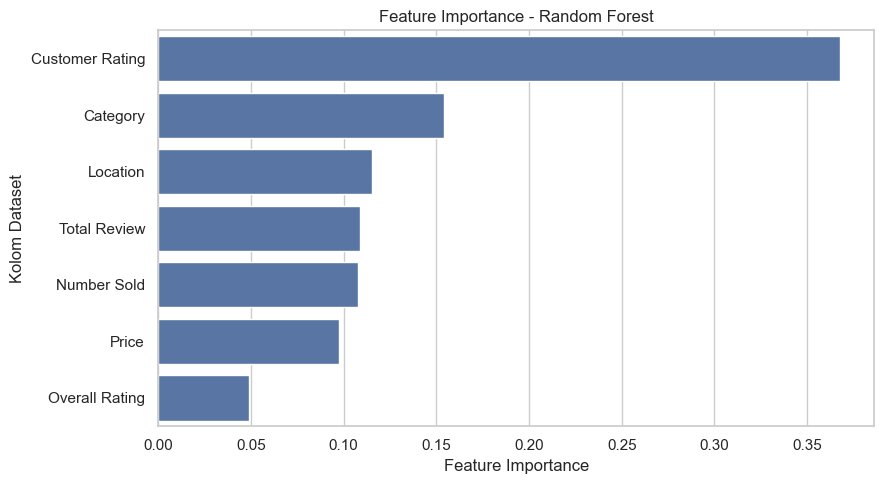

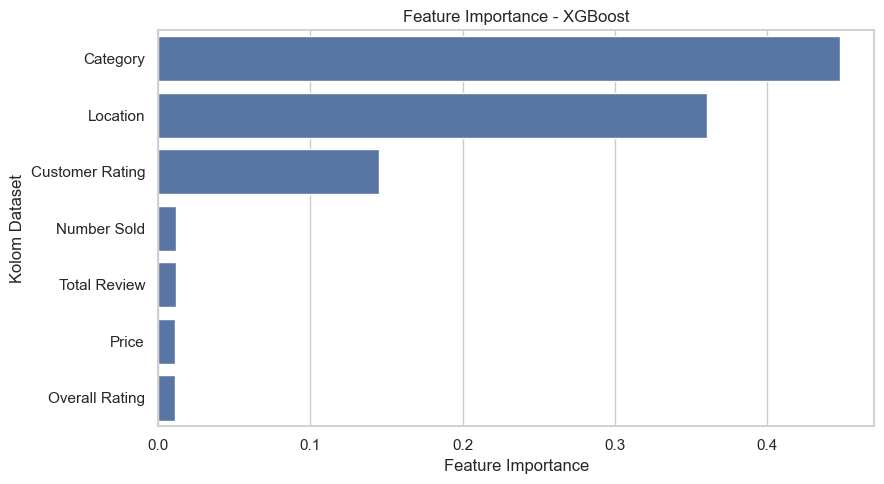

In [36]:
# Feature Importance Berdasarkan Kolom Dataset
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

features = [
    "Category", "Location", "Price", "Overall Rating",
    "Number Sold", "Total Review", "Customer Rating"
]

categorical_features = ["Category", "Location"]
numeric_features = [col for col in features if col not in categorical_features]

# Data training
X_tab_train = df_clean[features].iloc[train_idx].copy()
y_tab_train = le.transform(df_clean["Emotion"].iloc[train_idx].astype(str))

# Preprocessing
preprocessor = ColumnTransformer([
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical_features),
    ("num", SimpleImputer(strategy="median"), numeric_features)
])

X_train_encoded = preprocessor.fit_transform(X_tab_train)

encoded_names = preprocessor.get_feature_names_out()

# Model
models = {
    "Random Forest": RandomForestClassifier(
        n_estimators=400,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),
    "XGBoost": XGBClassifier(
        objective="multi:softprob",
        num_class=len(class_names),
        n_estimators=350,
        max_depth=6,
        learning_rate=0.08,
        eval_metric="mlogloss",
        tree_method="hist",
        random_state=42,
        n_jobs=-1
    )
}

# Menggabungkan importance berdasarkan kolom asli
column_groups = {
    col: [
        i for i, name in enumerate(encoded_names)
        if name.startswith(f"cat__{col}_") or name == f"num__{col}"
    ]
    for col in features
}

for model_name, model in models.items():

    if model_name == "XGBoost":
        weights = compute_sample_weight("balanced", y_tab_train)
        model.fit(X_train_encoded, y_tab_train, sample_weight=weights)
    else:
        model.fit(X_train_encoded, y_tab_train)

    importance = model.feature_importances_

    feature_importance = pd.DataFrame({
        "Kolom": list(column_groups.keys()),
        "Importance": [
            importance[idx].sum()
            for idx in column_groups.values()
        ]
    }).sort_values("Importance", ascending=False)

    plt.figure(figsize=(9, 5))
    sns.barplot(
        data=feature_importance,
        x="Importance",
        y="Kolom"
    )

    plt.title(f"Feature Importance - {model_name}")
    plt.xlabel("Feature Importance")
    plt.ylabel("Kolom Dataset")
    plt.tight_layout()
    plt.show()

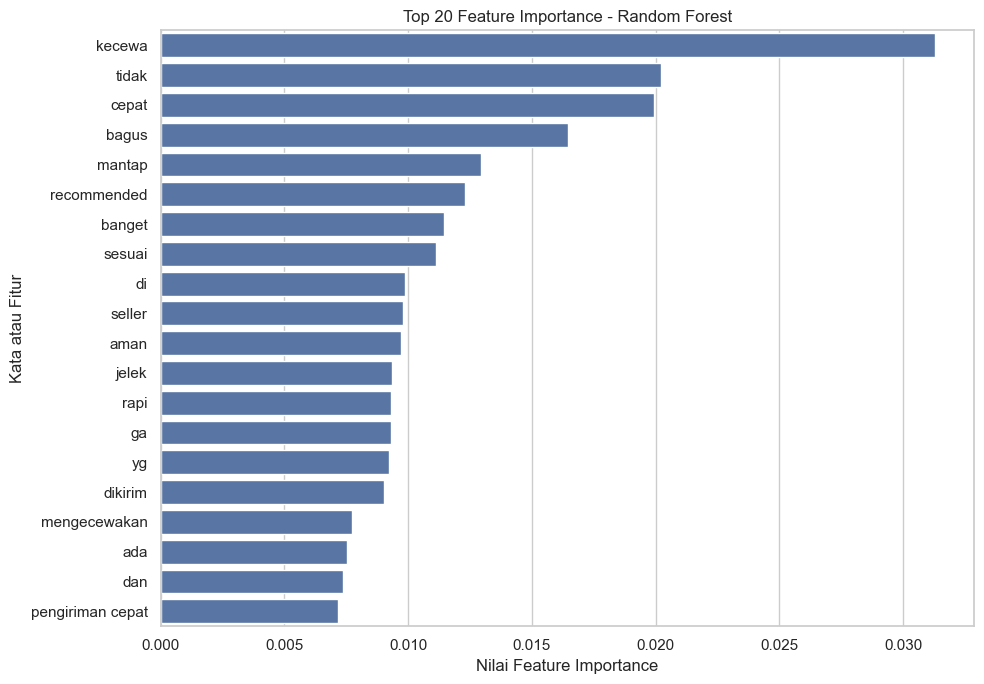

In [37]:
rf_importance = rf_model.feature_importances_

# Menggabungkan nama fitur dengan nilai importance
rf_feature_importance = pd.DataFrame({
    "Fitur": selected_terms,
    "Importance": rf_importance
})

# Mengurutkan fitur berdasarkan tingkat kepentingannya
rf_feature_importance = rf_feature_importance.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

# Menampilkan 20 fitur paling penting
top_rf_features = rf_feature_importance.head(20)

# Visualisasi Feature Importance
plt.figure(figsize=(10, 7))
sns.barplot(
    data=top_rf_features,
    x="Importance",
    y="Fitur"
)
plt.title("Top 20 Feature Importance - Random Forest")
plt.xlabel("Nilai Feature Importance")
plt.ylabel("Kata atau Fitur")
plt.tight_layout()
plt.show()


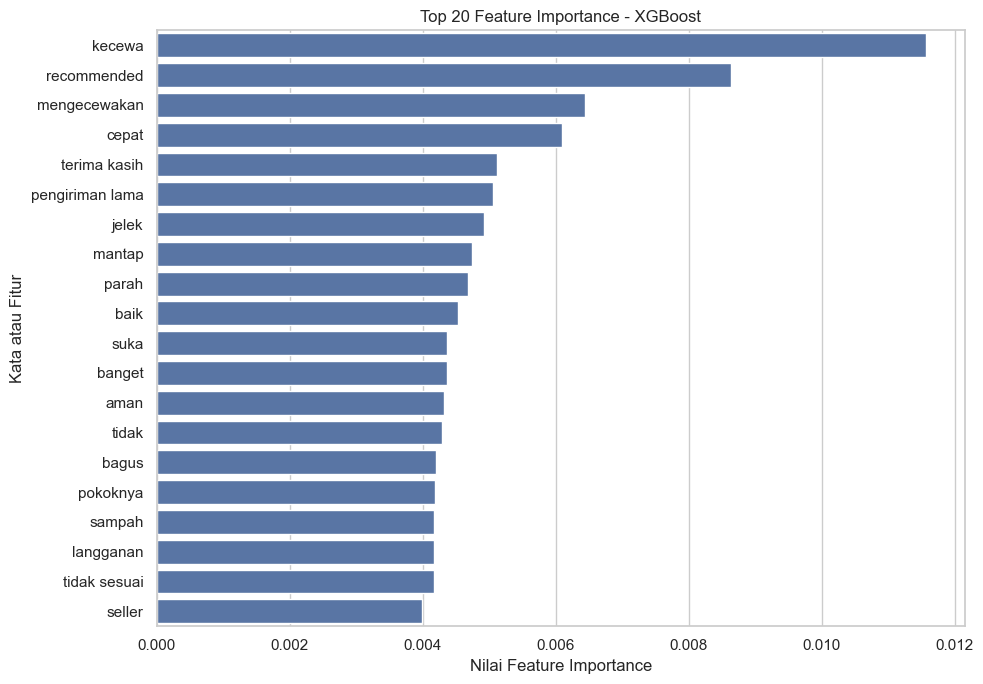

In [38]:
# Feature Importance - XGBoost
xgb_importance = xgb_model.feature_importances_

xgb_feature_importance = pd.DataFrame({
    "Fitur": selected_terms,
    "Importance": xgb_importance
})

xgb_feature_importance = xgb_feature_importance.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

plt.figure(figsize=(10, 7))
sns.barplot(
    data=xgb_feature_importance.head(20),
    x="Importance",
    y="Fitur"
)
plt.title("Top 20 Feature Importance - XGBoost")
plt.xlabel("Nilai Feature Importance")
plt.ylabel("Kata atau Fitur")
plt.tight_layout()
plt.show()

# Fase 5 — Evaluation (CRISP-DM)

## Evaluasi model

,Accuracy,Precision Macro,Recall Macro,F1 Macro,F1 Weighted
Model,,,,,
Baseline (kelas mayoritas),0.3360,0.0672,0.2000,0.1006,0.1690
Random Forest,0.6227,0.6009,0.6048,0.5960,0.6264
XGBoost,0.6046,0.5730,0.5750,0.5708,0.6102


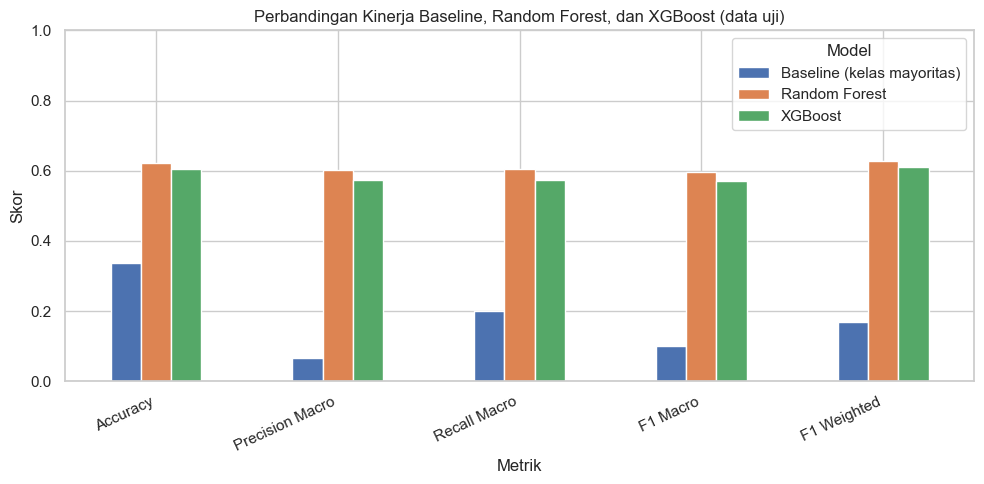

In [39]:
from sklearn.dummy import DummyClassifier

def evaluate_model(name, y_true, y_pred):
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision Macro": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "Recall Macro": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "F1 Macro": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "F1 Weighted": f1_score(y_true, y_pred, average="weighted", zero_division=0)
    }

# Baseline: selalu menebak kelas mayoritas di data train.
baseline = DummyClassifier(strategy="most_frequent").fit(X_train_selected, y_train_array)
baseline_pred = baseline.predict(X_test_selected)

results = pd.DataFrame([
    evaluate_model("Baseline (kelas mayoritas)", y_test, baseline_pred),
    evaluate_model("Random Forest", y_test, rf_pred),
    evaluate_model("XGBoost", y_test, xgb_pred)
]).set_index("Model")
display(results.round(4))

fig, ax = plt.subplots(figsize=(10, 5))
results[["Accuracy", "Precision Macro", "Recall Macro", "F1 Macro", "F1 Weighted"]].T.plot(kind="bar", ax=ax)
ax.set_title("Perbandingan Kinerja Baseline, Random Forest, dan XGBoost (data uji)")
ax.set_ylabel("Skor")
ax.set_xlabel("Metrik")
ax.set_ylim(0, 1)
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

### Interpretasi metrik evaluasi

- **Accuracy**: proporsi seluruh prediksi yang benar.
- **Precision Macro**: rata-rata precision dari lima kelas; menunjukkan ketepatan prediksi pada tiap emosi dengan bobot kelas setara.
- **Recall Macro**: rata-rata recall dari lima kelas; menunjukkan kemampuan menemukan ulasan pada tiap emosi.
- **F1 Macro**: rata-rata F1 lima kelas; metrik utama karena kelas tidak seimbang.
- **F1 Weighted**: rata-rata F1 dengan bobot sesuai jumlah sampel tiap kelas, sehingga kelas mayoritas lebih berpengaruh.

Contoh interpretasi: Macro F1 sebesar 0,60 berarti rata-rata harmonik precision dan recall antar lima kelas adalah sekitar 0,60. Angka ini bukan berarti 60% seluruh ulasan diprediksi benar; proporsi prediksi benar secara keseluruhan ditunjukkan oleh Accuracy.

### Contoh hasil prediksi awal

Tabel berikut menampilkan 10 ulasan acak dari data uji beserta label asli dan prediksi kedua model.

In [40]:
contoh = pd.DataFrame({
    "Ulasan": X_test.reset_index(drop=True).str.slice(0, 80),
    "Label asli": le.inverse_transform(y_test),
    "Prediksi RF": le.inverse_transform(rf_pred),
    "Prediksi XGBoost": le.inverse_transform(xgb_pred),
})
contoh["RF benar"] = contoh["Label asli"] == contoh["Prediksi RF"]
contoh["XGB benar"] = contoh["Label asli"] == contoh["Prediksi XGBoost"]
display(contoh.sample(10, random_state=SEED).reset_index(drop=True))

,Ulasan,Label asli,Prediksi RF,Prediksi XGBoost,RF benar,XGB benar
0,pengiriman sangat lama padahal didalam jabodet...,Fear,Fear,Fear,True,True
1,barang nya tipis...tapi y udhlah brg udh d terima,Sadness,Happy,Sadness,False,True
2,kualitas bahan bagus ??. jahitannya rapi. warn...,Happy,Happy,Happy,True,True
3,"kemasannya memakai plastik, mudah mangap, rawa...",Fear,Fear,Fear,True,True
4,"barang sampe cepat, packaging rapi dan aman.cu...",Sadness,Happy,Sadness,False,True
5,udh top banget lah beli disini juara ke oriann...,Love,Love,Love,True,True
6,"brgnya cpt sampai, packing maxi, trims utk sel...",Love,Love,Love,True,True
7,cepat pwngirima..tp sayanng beli 6 buku tp ada...,Sadness,Fear,Fear,False,False
8,gak nyaman dipakai.,Sadness,Happy,Happy,False,False
9,pengirimannya cepat rapi makasih,Love,Happy,Happy,False,False


### Tabel perbandingan akhir

Satu tabel merangkum seluruh model: parameter terbaik, hasil validasi silang (CV), hasil validation set, dan hasil data uji.

In [41]:
# Skor baseline pada validation set (kelas mayoritas subtraining).
base_val = DummyClassifier(strategy="most_frequent").fit(X_sub_selected, y_sub).predict(X_val_selected)

cv_best = {
    "Random Forest": tuning_df[tuning_df.Model == "Random Forest"]["Macro F1 CV (rata-rata)"].max(),
    "XGBoost": tuning_df[tuning_df.Model == "XGBoost"]["Macro F1 CV (rata-rata)"].max(),
}
summary = pd.DataFrame([
    {"Model": "Baseline (kelas mayoritas)", "Parameter terbaik": "-",
     "Macro F1 CV": np.nan,
     "Macro F1 validasi": f1_score(y_val, base_val, average="macro", zero_division=0),
     "Accuracy uji": results.loc["Baseline (kelas mayoritas)", "Accuracy"],
     "Macro F1 uji": results.loc["Baseline (kelas mayoritas)", "F1 Macro"],
     "F1 Weighted uji": results.loc["Baseline (kelas mayoritas)", "F1 Weighted"]},
    {"Model": "Random Forest", "Parameter terbaik": str(best_rf_params),
     "Macro F1 CV": cv_best["Random Forest"],
     "Macro F1 validasi": validation_results.loc["Random Forest", "Macro F1"],
     "Accuracy uji": results.loc["Random Forest", "Accuracy"],
     "Macro F1 uji": results.loc["Random Forest", "F1 Macro"],
     "F1 Weighted uji": results.loc["Random Forest", "F1 Weighted"]},
    {"Model": "XGBoost", "Parameter terbaik": str(best_xgb_params),
     "Macro F1 CV": cv_best["XGBoost"],
     "Macro F1 validasi": validation_results.loc["XGBoost", "Macro F1"],
     "Accuracy uji": results.loc["XGBoost", "Accuracy"],
     "Macro F1 uji": results.loc["XGBoost", "F1 Macro"],
     "F1 Weighted uji": results.loc["XGBoost", "F1 Weighted"]},
]).set_index("Model")
display(summary.round(4))
print("Model terpilih (berdasarkan Macro F1 validasi):", best_model_name)

,Parameter terbaik,Macro F1 CV,Macro F1 validasi,Accuracy uji,Macro F1 uji,F1 Weighted uji
Model,,,,,,
Baseline (kelas mayoritas),-,NaN,0.0921,0.3360,0.1006,0.1690
Random Forest,"{'n_estimators': 400, 'max_features': 'log2', ...",0.5531,0.5785,0.6227,0.5960,0.6264
XGBoost,"{'max_depth': 3, 'n_estimators': 350}",0.5457,0.5727,0.6046,0.5708,0.6102


Model terpilih (berdasarkan Macro F1 validasi): Random Forest


## Clasification report

In [42]:
for model_name, prediction in [("Random Forest", rf_pred), ("XGBoost", xgb_pred)]:
    print(f"\nClassification Report — {model_name}")
    print(classification_report(y_test, prediction, labels=np.arange(len(class_names)),
                                target_names=class_names, zero_division=0, digits=4))


Classification Report — Random Forest
              precision    recall  f1-score   support

       Anger     0.4813    0.6016    0.5347       128
        Fear     0.4624    0.5478    0.5015       157
       Happy     0.7743    0.7395    0.7565       334
        Love     0.5531    0.6306    0.5893       157
     Sadness     0.7333    0.5046    0.5978       218

    accuracy                         0.6227       994
   macro avg     0.6009    0.6048    0.5960       994
weighted avg     0.6434    0.6227    0.6264       994


Classification Report — XGBoost
              precision    recall  f1-score   support

       Anger     0.4326    0.4766    0.4535       128
        Fear     0.4503    0.5478    0.4943       157
       Happy     0.7821    0.7305    0.7554       334
        Love     0.5029    0.5605    0.5301       157
     Sadness     0.6971    0.5596    0.6209       218

    accuracy                         0.6046       994
   macro avg     0.5730    0.5750    0.5708       994
weigh

## Confusion matrix kedua model

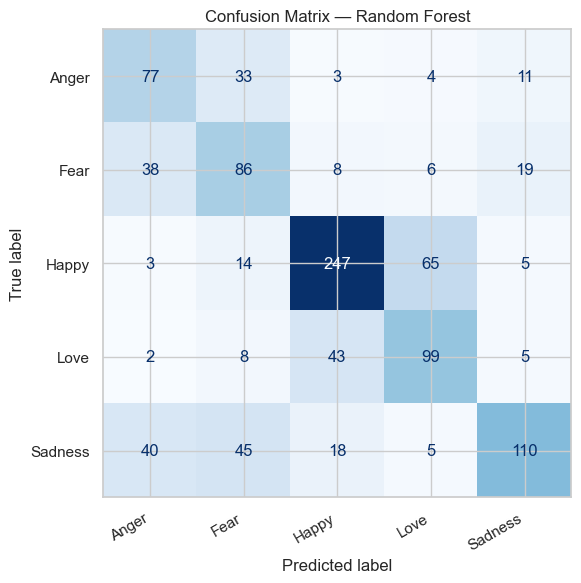

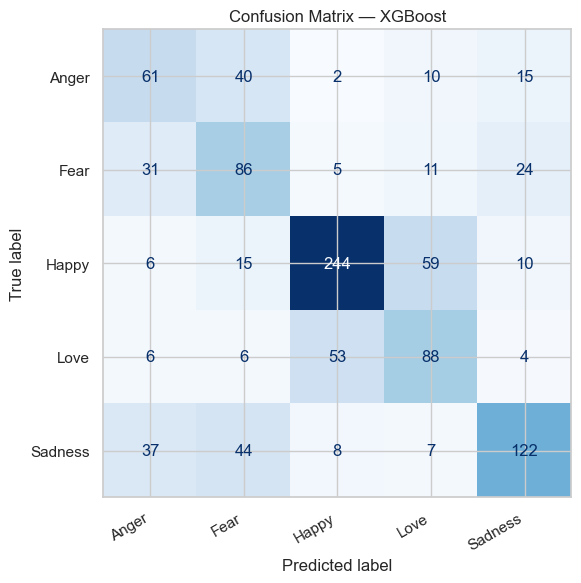

In [43]:
for model_name, prediction in [("Random Forest", rf_pred), ("XGBoost", xgb_pred)]:    
    cm = confusion_matrix(y_test, prediction, labels=np.arange(len(class_names)))
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
    fig, ax = plt.subplots(figsize=(7, 6))
    disp.plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)
    ax.set_title(f"Confusion Matrix — {model_name}")
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.show()

### Cara membaca confusion matrix

Baris menunjukkan label emosi sebenarnya dan kolom menunjukkan hasil prediksi. Angka pada diagonal adalah prediksi benar, sedangkan angka di luar diagonal menunjukkan pasangan kelas yang tertukar. Perhatikan kelas dengan jumlah kesalahan terbesar untuk mengetahui emosi yang masih sulit dibedakan. Kesalahan tersebut dapat terjadi karena kosakata antar-emosi saling tumpang tindih, konteks kalimat terbatas, atau bahasa informal.

## Analisis performa per kelas dan pemilihan model

In [44]:
reports = {}
for name, pred in [("Random Forest", rf_pred), ("XGBoost", xgb_pred)]:
    rep = classification_report(
        y_test, pred,
        labels=np.arange(len(class_names)),
        target_names=class_names,
        output_dict=True,
        zero_division=0
    )
    reports[name] = pd.DataFrame(rep).T.loc[
        class_names, ["precision", "recall", "f1-score", "support"]
    ]
    print(name)
    display(reports[name].round(4))

print("Model terpilih berdasarkan Macro F1 validation:", best_model_name)
print(
    "Hasil testing digunakan sebagai evaluasi akhir. "
    "Jangan memilih ulang model berdasarkan skor testing."
)

Random Forest


,precision,recall,f1-score,support
Anger,0.4812,0.6016,0.5347,128.0
Fear,0.4624,0.5478,0.5015,157.0
Happy,0.7743,0.7395,0.7565,334.0
Love,0.5531,0.6306,0.5893,157.0
Sadness,0.7333,0.5046,0.5978,218.0


XGBoost


,precision,recall,f1-score,support
Anger,0.4326,0.4766,0.4535,128.0
Fear,0.4503,0.5478,0.4943,157.0
Happy,0.7821,0.7305,0.7554,334.0
Love,0.5029,0.5605,0.5301,157.0
Sadness,0.6971,0.5596,0.6209,218.0


Model terpilih berdasarkan Macro F1 validation: Random Forest
Hasil testing digunakan sebagai evaluasi akhir. Jangan memilih ulang model berdasarkan skor testing.


### Interpretasi metrik per kelas

Classification report memuat precision, recall, F1-score, dan support untuk masing-masing emosi. Support menunjukkan jumlah sampel aktual pada kelas tersebut di data uji. Bandingkan F1-score per kelas untuk mengidentifikasi kelas yang paling mudah dan paling sulit dikenali. Perbedaan support perlu diperhatikan saat menafsirkan skor per kelas.

## Interpretasi hasil modeling

Sel berikut menyusun interpretasi **langsung dari hasil yang sedang dijalankan**, sehingga angka pada teks selalu sama dengan angka pada tabel di atas.

In [45]:
from sklearn.metrics import confusion_matrix

sel_pred = xgb_pred if best_model_name == "XGBoost" else rf_pred
other_name = "Random Forest" if best_model_name == "XGBoost" else "XGBoost"

f1_sel = results.loc[best_model_name, "F1 Macro"]
f1_base = results.loc["Baseline (kelas mayoritas)", "F1 Macro"]
acc_sel = results.loc[best_model_name, "Accuracy"]
acc_base = results.loc["Baseline (kelas mayoritas)", "Accuracy"]

rep = classification_report(y_test, sel_pred, labels=np.arange(len(class_names)),
                            target_names=class_names, output_dict=True, zero_division=0)
per_class = pd.Series({c: rep[c]["f1-score"] for c in class_names}).sort_values()
worst, best = per_class.index[0], per_class.index[-1]

cm = confusion_matrix(y_test, sel_pred, labels=np.arange(len(class_names)))
conf = [(class_names[i], class_names[j], cm[i, j])
        for i in range(len(class_names)) for j in range(len(class_names)) if i != j]
conf = sorted(conf, key=lambda t: t[2], reverse=True)[:3]

print(f"1. Model terpilih (validasi): {best_model_name}. Pada data uji: Accuracy {acc_sel:.3f}, Macro F1 {f1_sel:.3f}.")
print(f"2. Baseline hanya mencapai Accuracy {acc_base:.3f} dan Macro F1 {f1_base:.3f}; "
      f"model naik {f1_sel - f1_base:+.3f} pada Macro F1, jadi model benar-benar mempelajari pola emosi.")
status = "TERCAPAI" if f1_sel >= TARGET_MACRO_F1 else "BELUM TERCAPAI"
print(f"3. Target Business Understanding (Macro F1 >= {TARGET_MACRO_F1:.2f}): {status}.")
print(f"4. Kelas paling mudah dikenali: {best} (F1 {per_class[best]:.3f}). "
      f"Kelas tersulit: {worst} (F1 {per_class[worst]:.3f}).")
print("5. Kesalahan terbanyak (label asli -> prediksi): " +
      "; ".join(f"{a} -> {b} ({n} ulasan)" for a, b, n in conf) + ".")
f1_other = results.loc[other_name, "F1 Macro"]
print(f"6. Pembanding ({other_name}) memperoleh Macro F1 uji {f1_other:.3f} "
      f"(selisih {f1_other - f1_sel:+.3f} terhadap model terpilih).")

# Apakah tiga kriteria (validasi, CV, uji) sepakat tentang model terbaik?
val_leader = validation_results["Macro F1"].idxmax()
cv_leader = max(cv_best, key=cv_best.get)
test_leader = results.loc[["Random Forest", "XGBoost"], "F1 Macro"].idxmax()
val_gap = validation_results["Macro F1"].max() - validation_results["Macro F1"].min()
print(f"7. Model unggul menurut validasi: {val_leader} (selisih hanya {val_gap:.4f}); "
      f"menurut CV: {cv_leader}; menurut data uji: {test_leader}.")
if len({val_leader, cv_leader, test_leader}) > 1:
    print("   Ketiga kriteria tidak sepakat dan selisihnya kecil, sehingga kedua model dapat dianggap "
          "setara. Aturan pemilihan tetap memakai validation agar data uji tidak ikut menentukan model.")

# Dampak tuning: parameter awal vs parameter terbaik (Macro F1 CV).
print("8. Dampak tuning (Macro F1 CV, parameter awal -> terbaik):")
for name in ["Random Forest", "XGBoost"]:
    d = tuning_df[tuning_df.Model == name]
    awal = d[d["Parameter awal"]]["Macro F1 CV (rata-rata)"].iloc[0]
    terbaik = d["Macro F1 CV (rata-rata)"].max()
    print(f"   - {name}: {awal:.4f} -> {terbaik:.4f} ({terbaik - awal:+.4f})")

1. Model terpilih (validasi): Random Forest. Pada data uji: Accuracy 0.623, Macro F1 0.596.
2. Baseline hanya mencapai Accuracy 0.336 dan Macro F1 0.101; model naik +0.495 pada Macro F1, jadi model benar-benar mempelajari pola emosi.
3. Target Business Understanding (Macro F1 >= 0.50): TERCAPAI.
4. Kelas paling mudah dikenali: Happy (F1 0.757). Kelas tersulit: Fear (F1 0.501).
5. Kesalahan terbanyak (label asli -> prediksi): Happy -> Love (65 ulasan); Sadness -> Fear (45 ulasan); Love -> Happy (43 ulasan).
6. Pembanding (XGBoost) memperoleh Macro F1 uji 0.571 (selisih -0.025 terhadap model terpilih).
7. Model unggul menurut validasi: Random Forest (selisih hanya 0.0058); menurut CV: Random Forest; menurut data uji: Random Forest.
8. Dampak tuning (Macro F1 CV, parameter awal -> terbaik):
   - Random Forest: 0.4933 -> 0.5531 (+0.0597)
   - XGBoost: 0.5451 -> 0.5457 (+0.0006)


**Makna hasil:**
- Akurasi di kisaran 60% pada 5 kelas menunjukkan model lebih baik daripada baseline kelas mayoritas, tetapi masih menyisakan kesalahan prediksi.
- Kinerja per kelas tidak merata. Berdasarkan output evaluasi saat ini, kelas Happy memiliki F1-score tertinggi, sedangkan Fear memiliki F1-score terendah. Gunakan Classification Report terbaru jika hasil berubah setelah notebook dijalankan ulang.
- Kesalahan antarkelas dapat terjadi karena beberapa emosi memiliki ungkapan bahasa yang mirip. Ulasan pendek dan informal juga sering tidak memberikan petunjuk emosi yang tegas.
- Dampak tuning perlu dibaca per model. Jika kenaikannya kecil, batas kinerja kemungkinan juga dipengaruhi representasi TF-IDF yang belum memahami konteks kalimat dan ambiguitas label.
- Jika selisih antar model kecil, hindari klaim bahwa satu model jauh lebih unggul. Jelaskan skor validation sebagai dasar pemilihan model dan skor testing sebagai evaluasi akhir.

# Fase 6 — Deployment (CRISP-DM)

Tahap deployment diwujudkan sebagai implementasi awal (*local deployment*). Model yang dipilih berdasarkan Macro F1 pada validation set disimpan bersama komponen preprocessing. Hasil testing hanya digunakan untuk melaporkan performa akhir, bukan untuk memilih model.

In [46]:
import joblib
from pathlib import Path

# Pemilihan model mengikuti hasil validation, bukan skor testing.
if best_model_name == "Random Forest":
    deployment_model = rf_model
else:
    deployment_model = xgb_model

deployment_artifact = {
    "model": deployment_model,
    "tfidf": tfidf,
    "selector": selector,
    "label_encoder": le,
    "model_name": best_model_name,
    "class_names": list(class_names),
    "best_k": best_k,
    "text_normalization": (
        "replace U+FFFD, lowercase, dan rapikan whitespace"
    )
}

artifact_dir = Path("deployment_artifacts")
artifact_dir.mkdir(exist_ok=True)
artifact_path = artifact_dir / "model_klasifikasi_emosi_tokopedia.joblib"
joblib.dump(deployment_artifact, artifact_path)

print("Model terpilih :", best_model_name)
print("Jumlah fitur   :", best_k)
print("Lokasi artefak :", artifact_path.resolve())
print(f"Ukuran file    : {artifact_path.stat().st_size / 1024:.2f} KB")

Model terpilih : Random Forest
Jumlah fitur   : 3000
Lokasi artefak : D:\proyekds\deployment_artifacts\model_klasifikasi_emosi_tokopedia.joblib
Ukuran file    : 6074.95 KB


### Fungsi inferensi untuk ulasan baru

Fungsi berikut memuat artefak hasil penyimpanan, menjalankan preprocessing dan transformasi fitur, lalu mengembalikan label emosi sesuai nama kelas asli pada dataset.

In [47]:
# Muat ulang artefak untuk menguji file hasil deployment.
loaded_artifact = joblib.load(artifact_path)

def predict_emotion(review, artifact=loaded_artifact):
    """Memprediksi label Emotion dari satu teks ulasan baru."""
    if not isinstance(review, str) or not review.strip():
        raise ValueError("Ulasan harus berupa teks dan tidak boleh kosong.")

    review_clean = normalize_review(review)
    review_tfidf = artifact["tfidf"].transform([review_clean])
    review_selected = artifact["selector"].transform(review_tfidf)
    predicted_code = artifact["model"].predict(review_selected)

    predicted_label = artifact["label_encoder"].inverse_transform(
        np.asarray(predicted_code, dtype=int)
    )[0]
    return predicted_label

contoh_ulasan = "Barangnya keren banget cok"
hasil_prediksi = predict_emotion(contoh_ulasan)

print("Ulasan        :", contoh_ulasan)
print("Prediksi emosi:", hasil_prediksi)

Ulasan        : Barangnya keren banget cok
Prediksi emosi: Love


### Prediksi beberapa ulasan sekaligus

Fungsi ini dapat digunakan untuk mencoba model pada daftar ulasan. Hasil prediksi ditampilkan sebagai tabel agar mudah diperiksa.

In [48]:
def predict_emotions(reviews, artifact=loaded_artifact):
    """Memprediksi emosi untuk sekumpulan teks ulasan."""
    if not reviews:
        return pd.DataFrame(columns=["Customer Review", "Predicted Emotion"])

    if any(not isinstance(review, str) or not review.strip() for review in reviews):
        raise ValueError("Setiap ulasan harus berupa teks dan tidak boleh kosong.")

    cleaned_reviews = [normalize_review(review) for review in reviews]
    features = artifact["tfidf"].transform(cleaned_reviews)
    features = artifact["selector"].transform(features)
    predicted_codes = artifact["model"].predict(features)
    predicted_labels = artifact["label_encoder"].inverse_transform(
        np.asarray(predicted_codes, dtype=int)
    )

    return pd.DataFrame({
        "Customer Review": reviews,
        "Predicted Emotion": predicted_labels
    })

ulasan_baru = [
    "Produk bagus dan kualitasnya memuaskan.",
    "Pengiriman sangat lama dan barang tidak sesuai.",
    "Saya kecewa dengan pelayanan toko.",
    "Barangnya jelek banget cok",
    "saya suka sama produknya"
]

hasil_batch = predict_emotions(ulasan_baru)
display(hasil_batch)

,Customer Review,Predicted Emotion
0,Produk bagus dan kualitasnya memuaskan.,Happy
1,Pengiriman sangat lama dan barang tidak sesuai.,Fear
2,Saya kecewa dengan pelayanan toko.,Sadness
3,Barangnya jelek banget cok,Anger
4,saya suka sama produknya,Love


**Catatan penggunaan:** file `model_klasifikasi_emosi_tokopedia.joblib` harus disimpan bersama versi library yang kompatibel. Untuk menjalankan inferensi di lingkungan lain, instal dependensi yang digunakan pada notebook (`pandas`, `numpy`, `scikit-learn`, `xgboost`, dan `joblib`), lalu muat artefak dengan `joblib.load()`. Jangan memuat file `joblib` dari sumber yang tidak dipercaya karena proses deserialisasi dapat menjalankan kode berbahaya.

## Kesimpulan dan saran

**Kesimpulan** (angka lengkap ada pada tabel perbandingan akhir dan interpretasi di atas):
1. Klasifikasi emosi ulasan Tokopedia ke lima kelas dengan TF-IDF, Random Forest, dan XGBoost berhasil dibangun tanpa kebocoran data (split berbasis produk, TF-IDF dan seleksi fitur di-fit hanya pada data latih).
2. Parameter model dipilih secara sistematis dengan GroupKFold, dan model dipilih memakai Macro F1 pada validation set. Data uji hanya dipakai untuk pelaporan akhir.
3. Kedua model melampaui baseline kelas mayoritas dengan selisih besar, tetapi selisih antar kedua model kecil sehingga keduanya dapat dianggap setara. Kinerja per kelas tidak merata: kelas dengan data terbanyak lebih mudah dikenali daripada kelas dengan data sedikit.
4. Hasil bersifat reproducible pada versi library yang sama (`SEED = 42`).

**Keterbatasan:** satu split uji (994 ulasan), teks identik lintas produk masih ada, TF-IDF tidak menangkap konteks, dan jumlah fitur dipilih memakai Naive Bayes sebagai alat bantu.

**Saran pengembangan:**
1. Evaluasi pada data ulasan yang lebih baru dan lebih beragam.
2. Perluas ruang pencarian parameter (misalnya `learning_rate`, `subsample`) bila waktu komputasi memungkinkan.
3. Periksa contoh salah klasifikasi untuk memahami ambiguitas bahasa informal, sarkasme, dan ulasan singkat.
4. Bandingkan dengan model representasi bahasa Indonesia atau transformer (misalnya IndoBERT).
5. Pertimbangkan fitur tambahan hanya jika tersedia saat prediksi dan tidak menyebabkan target leakage.

## Catatan metodologis

- `Sentiment` tidak digunakan sebagai prediktor karena berasosiasi langsung dengan kelompok label `Emotion`.
- `Product Name` digunakan hanya untuk group splitting, bukan sebagai fitur prediksi.
- Data dibagi dua tahap: train-test berbasis produk, lalu train dibagi menjadi subtraining-validation berbasis produk.
- TF-IDF pada validasi internal di-fit hanya pada subtraining.
- Pada setiap lipatan GroupKFold, TF-IDF dan Chi-Square di-fit hanya pada bagian latih lipatan.
- Jumlah fitur Chi-Square `k=3.000` ditetapkan sebagai konfigurasi eksperimen akhir, bukan dipilih menggunakan validation set.
- Hyperparameter model dipilih dengan GroupKFold (5 lipatan) pada subtraining.
- Model dipilih berdasarkan Macro F1 validation.
- Setelah model dipilih, TF-IDF, selector, dan model di-fit ulang pada seluruh data training.
- Data testing hanya digunakan untuk evaluasi akhir.
- Urutan label evaluasi selalu mengikuti `LabelEncoder.classes_`.
- TF-IDF menggunakan normalisasi L2; StandardScaler/MinMaxScaler tidak ditambahkan pada matriks teks sparse.
- Class weighting tidak mengubah jumlah sampel.
- Duplikasi teks yang sama pada produk berbeda diperiksa dan dilaporkan; tidak otomatis dihapus.
- Nilai numerik ekstrem tidak otomatis dihapus.
- Status lisensi perlu dirujuk ke halaman resmi dataset, bukan disimpulkan dari CSV.
- Seluruh proses acak memakai `SEED = 42`; hasil yang persis sama diharapkan pada versi library dan lingkungan yang sama (versi dicetak pada sel setup).

## Ringkasan keputusan akhir (otomatis dari hasil eksekusi)

Sel berikut menghasilkan ringkasan kuantitatif berdasarkan objek evaluasi yang dibentuk pada tahap sebelumnya. Jalankan notebook dari atas ke bawah agar nilai yang ditampilkan berasal dari eksekusi terbaru.

In [49]:
# Ringkasan final dihitung dari metrik hasil test yang sudah dibuat.
final_model = best_model_name
final_macro_f1 = float(results.loc[final_model, "F1 Macro"])
final_accuracy = float(results.loc[final_model, "Accuracy"])
baseline_macro_f1 = float(results.loc["Baseline (kelas mayoritas)", "F1 Macro"])
target_status = "TERCAPAI" if final_macro_f1 >= TARGET_MACRO_F1 else "BELUM TERCAPAI"

print("RINGKASAN HASIL PENELITIAN")
print(f"Model terpilih berdasarkan validation : {final_model}")
print(f"Accuracy pada test                   : {final_accuracy:.4f} ({final_accuracy*100:.2f}%)")
print(f"Macro F1 pada test                    : {final_macro_f1:.4f} ({final_macro_f1*100:.2f}%)")
print(f"Macro F1 baseline                     : {baseline_macro_f1:.4f} ({baseline_macro_f1*100:.2f}%)")
print(f"Selisih Macro F1 dari baseline        : {final_macro_f1-baseline_macro_f1:+.4f}")
print(f"Target Macro F1 >= {TARGET_MACRO_F1:.2f} : {target_status}")
print()
print("Interpretasi:")
print(f"Model terpilih memperoleh Macro F1 {final_macro_f1:.2f}. "
      "Nilai ini merupakan rata-rata F1 dari lima kelas emosi dengan bobot kelas setara.")
print(f"Accuracy {final_accuracy:.2f} berarti sekitar {final_accuracy*100:.1f}% prediksi pada data uji tepat.")
print("Keputusan model final didasarkan pada validation set; metrik test hanya digunakan sebagai evaluasi akhir.")


RINGKASAN HASIL PENELITIAN
Model terpilih berdasarkan validation : Random Forest
Accuracy pada test                   : 0.6227 (62.27%)
Macro F1 pada test                    : 0.5960 (59.60%)
Macro F1 baseline                     : 0.1006 (10.06%)
Selisih Macro F1 dari baseline        : +0.4954
Target Macro F1 >= 0.50 : TERCAPAI

Interpretasi:
Model terpilih memperoleh Macro F1 0.60. Nilai ini merupakan rata-rata F1 dari lima kelas emosi dengan bobot kelas setara.
Accuracy 0.62 berarti sekitar 62.3% prediksi pada data uji tepat.
Keputusan model final didasarkan pada validation set; metrik test hanya digunakan sebagai evaluasi akhir.
